# MO-IT128 - Data Mining Principles - MILESTONE 2
## S3107 | Team Nexus

**Authors/Analysts:**
- Abegail Imee Enriquez - Lead Developer & Data Analyst  
- Francisco Cabangon - MS 1 Team Leader & Data Analyst  
- Alvin Tubtub - Quality Assurance Analyst

# FinMark Corporation
## Project Clustering and Segmentation Report (Customer Segmentation)

This notebook builds directly on the outputs of **Milestone 1 (Preprocessing + Feature Engineering + EDA)** and applies **clustering** to segment FinMark customers into meaningful, data-driven groups.

**Milestone 2 workflow (high level):**
1. Load the **preprocessed + engineered customer-level dataset** from Milestone 1  
2. Review key EDA insights (what we learned + what it implies for segmentation)  
3. Select clustering-ready features (clean, relevant, and behavior-distinguishing)  
4. Standardize features and apply **PCA** to reduce dimensionality while preserving signal  
5. Train and tune a clustering model (**K-Means**)  
6. Visualize clusters and interpret customer segment profiles  
7. Export cluster labels and cluster profiles for reporting and downstream use


In [15]:
# =========================
# 0) Setup
# =========================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Display settings
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 140)

# ---- File paths (update if needed) ----
ENGINEERED_FEATURES_PATH = "FinMark_Customer_Features_Engineered.csv"

# Outputs
CLUSTERS_OUT_PATH = "FinMark_Customer_Clusters.csv"
PROFILES_OUT_PATH = "FinMark_Cluster_Profiles.csv"


## 1. Load the Engineered Customer-Level Dataset

In [16]:
# =========================
# 1) Load Milestone 1 Engineered Features
# =========================
from pathlib import Path
import pandas as pd

# Notebook is inside /Notebook, so project root is its parent folder
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebook" else Path.cwd()

# Based on your actual folder contents (Features/)
ENGINEERED_FEATURES_PATH = PROJECT_ROOT / "Features" / "customer_features.csv"

# Optional: if you prefer to start from the already-scaled features, switch to:
# ENGINEERED_FEATURES_PATH = PROJECT_ROOT / "Features" / "customer_features_scaled.csv"

if not ENGINEERED_FEATURES_PATH.exists():
    raise FileNotFoundError(
        f"File not found: {ENGINEERED_FEATURES_PATH}\n"
        "Check that your notebook is running from the Notebook/ folder, "
        "and that the file exists inside Features/."
    )

print("Reading engineered features from:", ENGINEERED_FEATURES_PATH)
df = pd.read_csv(ENGINEERED_FEATURES_PATH)

print("Rows, Columns:", df.shape)
display(df.head(3))

print("\nColumn list (first 40):")
print(df.columns.tolist()[:40])

Reading engineered features from: /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 2/Features/customer_features.csv
Rows, Columns: (993, 31)


,Customer_ID,total_spend,avg_spend,txn_count,Income_Group,active_days,tenure_days,recency_days,pct_weekend_txn,pct_business_hours_txn,avg_txn_hour,count_type_bill_payment,count_type_investment,count_type_loan_payment,count_type_purchase,pct_tod_Afternoon,pct_tod_Evening,pct_tod_Morning,pct_tod_Night,high_risk_txn_count,pct_high_risk_txn,feedback_count,satisfaction_mean,satisfaction_std,satisfaction_min,satisfaction_max,ltr_mean,ltr_std,ltr_min,ltr_max,feedback_sentiment_mean
0,1,16836.0,2806.0,6,High,6,180,26,0.17,0.17,6.83,3,1,1,1,0.17,0.17,0.0,0.67,3,0.5,2,8.50,2.12,7.0,10.0,9.00,0.00,9.0,9.0,5
1,2,4907.0,2453.5,2,Low,2,104,67,0.50,0.00,13.50,1,0,1,0,0.00,0.00,0.0,1.00,0,0.0,3,4.33,2.31,3.0,7.0,5.00,2.00,3.0,7.0,3
2,3,1538.0,1538.0,1,Low,1,0,150,0.00,0.00,23.00,1,0,0,0,0.00,0.00,0.0,1.00,0,0.0,3,8.33,2.08,6.0,10.0,3.67,3.79,1.0,8.0,5



Column list (first 40):
['Customer_ID', 'total_spend', 'avg_spend', 'txn_count', 'Income_Group', 'active_days', 'tenure_days', 'recency_days', 'pct_weekend_txn', 'pct_business_hours_txn', 'avg_txn_hour', 'count_type_bill_payment', 'count_type_investment', 'count_type_loan_payment', 'count_type_purchase', 'pct_tod_Afternoon', 'pct_tod_Evening', 'pct_tod_Morning', 'pct_tod_Night', 'high_risk_txn_count', 'pct_high_risk_txn', 'feedback_count', 'satisfaction_mean', 'satisfaction_std', 'satisfaction_min', 'satisfaction_max', 'ltr_mean', 'ltr_std', 'ltr_min', 'ltr_max', 'feedback_sentiment_mean']


## 2. Review of Key Insights from Milestone 1 (EDA Recap)

This subsection reconnects Milestone 2 to our Milestone 1 findings.  
We re-check the **same core dimensions** that showed the strongest segmentation potential:

- **Value:** total spend distribution and spend tiers (quartile-based)  
- **Usage intensity:** transaction frequency and average ticket size  
- **Timing habits:** business vs non-business hours, weekday vs weekend, time-of-day mix  
- **Experience signals:** satisfaction and likelihood-to-recommend (winsorized)  
- **Activity footprint:** mix of transaction types (loan, investment, bills, purchase)

> Note: Some numbers below are computed again from the engineered dataset to keep this notebook self-contained.


In [17]:
# =========================
# 2) Review of Key Insights from Milestone 1 (EDA Recap)
# =========================
# Helper: find a column by candidate names (case-insensitive)
def pick_col(df, candidates):
    cols = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in cols:
            return cols[cand.lower()]
    # fallback: partial match
    for cand in candidates:
        for c in df.columns:
            if cand.lower() in c.lower():
                return c
    return None

total_spend_col = pick_col(df, ["total_spend", "total_spending", "total_amount", "total_spend_amt"])
avg_spend_col   = pick_col(df, ["avg_spend", "avg_txn_amount", "average_spend", "mean_txn_amount"])
txn_count_col   = pick_col(df, ["txn_count", "transaction_count", "tx_count", "num_transactions"])

satisfaction_col = pick_col(df, ["avg_satisfaction", "mean_satisfaction", "satisfaction_mean", "satisfaction"])
ltr_col          = pick_col(df, ["avg_ltr", "mean_ltr", "likelihood_to_recommend", "recommendation", "ltr"])

income_group_col = pick_col(df, ["income_group", "income_tier", "income_segment", "tier"])

print("Detected key columns:")
print("  total_spend:", total_spend_col)
print("  avg_spend:", avg_spend_col)
print("  txn_count:", txn_count_col)
print("  satisfaction:", satisfaction_col)
print("  LTR:", ltr_col)
print("  income_group:", income_group_col)

# --- Basic stats (value + intensity) ---
if total_spend_col and txn_count_col:
    ts = df[total_spend_col]
    tc = df[txn_count_col]
    print("\nValue & intensity snapshot:")
    print(f"- Total spend: min={ts.min():,.2f}, max={ts.max():,.2f}, mean={ts.mean():,.2f}, median={ts.median():,.2f}, std={ts.std():,.2f}")
    print(f"- Transaction count: min={tc.min():,.0f}, max={tc.max():,.0f}, mean={tc.mean():,.2f}, median={tc.median():,.0f}, std={tc.std():,.2f}")

    # Correlation (spend vs frequency)
    corr = df[[total_spend_col, txn_count_col]].corr().iloc[0,1]
    print(f"- Corr(total_spend, txn_count): {corr:.2f}")

# --- Quartile tiers recap (if income group not already in df) ---
if total_spend_col:
    q1 = df[total_spend_col].quantile(0.25)
    q3 = df[total_spend_col].quantile(0.75)
    print(f"\nQuartile cutoffs from total spend: Q1={q1:,.0f} | Q3={q3:,.0f}")

    if income_group_col is None:
        def tier_from_spend(x):
            if x <= q1: return "Low"
            if x >= q3: return "High"
            return "Medium"
        df["income_group"] = df[total_spend_col].apply(tier_from_spend)
        income_group_col = "income_group"
        print("Income tier column created as 'income_group' (quartile-based).")

    tier_counts = df[income_group_col].value_counts(dropna=False)
    print("\nIncome tier distribution:")
    display(tier_counts.to_frame("count"))

    tier_means = df.groupby(income_group_col)[total_spend_col].mean().sort_values()
    print("\nMean total spend by tier:")
    display(tier_means.to_frame("mean_total_spend"))

# --- Satisfaction recap ---
if satisfaction_col:
    s = df[satisfaction_col]
    print("\nSatisfaction snapshot:")
    print(f"- mean={s.mean():.2f} | median={s.median():.2f} | std={s.std():.2f}")
if ltr_col:
    r = df[ltr_col]
    print("LTR snapshot:")
    print(f"- mean={r.mean():.2f} | median={r.median():.2f} | std={r.std():.2f}")

# --- Simple relationships (experience vs value/intensity) ---
rel_cols = [c for c in [satisfaction_col, ltr_col, total_spend_col, txn_count_col] if c]
if len(rel_cols) >= 3:
    print("\nSelected correlations (quick check):")
    corr_mat = df[rel_cols].corr()
    display(corr_mat)


Detected key columns:
  total_spend: total_spend
  avg_spend: avg_spend
  txn_count: txn_count
  satisfaction: satisfaction_mean
  LTR: ltr_mean
  income_group: Income_Group

Value & intensity snapshot:
- Total spend: min=286.00, max=37,281.00, mean=12,569.72, median=11,939.00, std=6,424.66
- Transaction count: min=1, max=13, mean=5.04, median=5, std=2.19
- Corr(total_spend, txn_count): 0.86

Quartile cutoffs from total spend: Q1=7,777 | Q3=16,531

Income tier distribution:


,count
Income_Group,
Medium,496
Low,249
High,248



Mean total spend by tier:


,mean_total_spend
Income_Group,
Low,5050.837349
Medium,11978.531250
High,21301.304435



Satisfaction snapshot:
- mean=5.60 | median=5.57 | std=1.41
LTR snapshot:
- mean=5.57 | median=5.67 | std=1.47

Selected correlations (quick check):


,satisfaction_mean,ltr_mean,total_spend,txn_count
satisfaction_mean,1.000000,-0.001566,0.011471,0.013296
ltr_mean,-0.001566,1.000000,-0.044354,-0.045873
total_spend,0.011471,-0.044354,1.000000,0.857769
txn_count,0.013296,-0.045873,0.857769,1.000000


### 2.1 Timing & Transaction-Footprint Signals (Quick Check)

Milestone 1 showed that **timing habits** and **transaction-type mix** can help distinguish groups beyond spend alone.  
Below we quickly summarize time-related engineered features (if present) and transaction-type mix features.


In [18]:
# =========================
# 2.1) Timing & Transaction-Footprint Signals
# =========================
# Identify likely temporal-share columns by keyword
temporal_keywords = ["business", "non_business", "weekday", "weekend", "morning", "afternoon", "evening", "night", "hour"]
temporal_cols = [c for c in df.columns if any(k in c.lower() for k in temporal_keywords)]
# Remove obvious non-numeric columns
temporal_cols = [c for c in temporal_cols if pd.api.types.is_numeric_dtype(df[c])]

print("Temporal-related numeric columns detected:", len(temporal_cols))
print(temporal_cols[:30])

if temporal_cols:
    print("\nTemporal feature averages (top 15 by mean):")
    means = df[temporal_cols].mean().sort_values(ascending=False).head(15)
    display(means.to_frame("mean"))

# Identify transaction-type columns (heuristic)
type_keywords = ["loan", "investment", "bill", "purchase", "type_"]
type_cols = [c for c in df.columns if any(k in c.lower() for k in type_keywords)]
type_cols = [c for c in type_cols if pd.api.types.is_numeric_dtype(df[c])]

print("\nTransaction-type numeric columns detected:", len(type_cols))
print(type_cols[:30])

if type_cols:
    print("\nAverage counts by type (top 10):")
    display(df[type_cols].mean().sort_values(ascending=False).head(10).to_frame("avg_count"))

# Optional: tier-level differences (if tier column exists)
if income_group_col and temporal_cols:
    print("\nTemporal means by income tier (selected columns if available):")
    show_cols = [c for c in temporal_cols if any(k in c.lower() for k in ["business", "weekend", "night", "avg", "hour"])][:8]
    if show_cols:
        display(df.groupby(income_group_col)[show_cols].mean())


Temporal-related numeric columns detected: 7
['pct_weekend_txn', 'pct_business_hours_txn', 'avg_txn_hour', 'pct_tod_Afternoon', 'pct_tod_Evening', 'pct_tod_Morning', 'pct_tod_Night']

Temporal feature averages (top 15 by mean):


,mean
avg_txn_hour,11.522437
pct_tod_Night,0.337795
pct_business_hours_txn,0.333243
pct_tod_Morning,0.293192
pct_weekend_txn,0.280493
pct_tod_Afternoon,0.206576
pct_tod_Evening,0.161923



Transaction-type numeric columns detected: 4
['count_type_bill_payment', 'count_type_investment', 'count_type_loan_payment', 'count_type_purchase']

Average counts by type (top 10):


,avg_count
count_type_loan_payment,1.288016
count_type_investment,1.251762
count_type_bill_payment,1.249748
count_type_purchase,1.245720



Temporal means by income tier (selected columns if available):


,pct_weekend_txn,pct_business_hours_txn,avg_txn_hour,pct_tod_Night
Income_Group,,,,
High,0.286210,0.329758,11.592016,0.328669
Low,0.275382,0.315823,11.565542,0.352048
Medium,0.280202,0.343730,11.466008,0.335202


## 3. Feature Engineering for Clustering (Feature Selection)

Clustering performs best when we use:
- **Customer-level behavioral features** (value, frequency, timing, footprint, tenure/recency, experience)
- **Numeric, clean, and comparable** scales (we will standardize later)
- Minimal leakage / IDs (we exclude customer identifiers and non-numeric labels)

In this step, we select a clustering feature set and briefly justify it based on Milestone 1 patterns.


In [19]:
# =========================
# 3) Select clustering-ready features
# =========================

# Columns to exclude (IDs / labels / obvious non-features)
exclude_keywords = [
    "customer", "id", "name", "email",
    "income_group", "income_tier", "tier",
    "cluster", "label"
]

exclude_cols = [c for c in df.columns if any(k in c.lower() for k in exclude_keywords)]

# Keep only numeric columns
numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
feature_cols = [c for c in numeric_cols if c not in exclude_cols]

print("Numeric columns:", len(numeric_cols))
print("Excluded columns:", len(set(exclude_cols)))
print("Selected feature columns for clustering:", len(feature_cols))

# Show top-variance features (helps answer: 'which features vary most across customers?')
var_series = df[feature_cols].std().sort_values(ascending=False)
print("\nTop 20 features by standard deviation (highest variation):")
display(var_series.head(20).to_frame("std"))

# Basic missingness check
missing = df[feature_cols].isna().mean().sort_values(ascending=False)
print("\nMissing rate (top 10):")
display(missing.head(10).to_frame("missing_rate"))

# Simple imputation (if needed)
X = df[feature_cols].copy()
X = X.fillna(X.median(numeric_only=True))

print("\nFinal feature matrix shape:", X.shape)


Numeric columns: 30
Excluded columns: 2
Selected feature columns for clustering: 29

Top 20 features by standard deviation (highest variation):


,std
total_spend,6424.663830
avg_spend,758.159268
tenure_days,51.351495
recency_days,36.396809
avg_txn_hour,3.631340
txn_count,2.185861
active_days,2.152117
feedback_count,2.014434
satisfaction_min,1.767106
ltr_min,1.762431



Missing rate (top 10):


,missing_rate
total_spend,0.0
pct_tod_Morning,0.0
ltr_max,0.0
ltr_min,0.0
ltr_std,0.0
ltr_mean,0.0
satisfaction_max,0.0
satisfaction_min,0.0
satisfaction_std,0.0
satisfaction_mean,0.0



Final feature matrix shape: (993, 29)


## 4. Dimensionality Reduction with PCA (Required Step)

Because our engineered dataset contains many related behavioral features (e.g., spend and frequency metrics, multiple timing shares, transaction-type counts), we apply **Principal Component Analysis (PCA)** after standardization.

**Why PCA first (before clustering)?**
- Reduces noise and multicollinearity (correlated features can dominate distance-based clustering)
- Compresses information into fewer dimensions, improving cluster stability
- Enables clear 2D/3D visualization for interpretation


PCA components to retain 90% variance: 14
Cumulative variance at 14 comps: 0.908


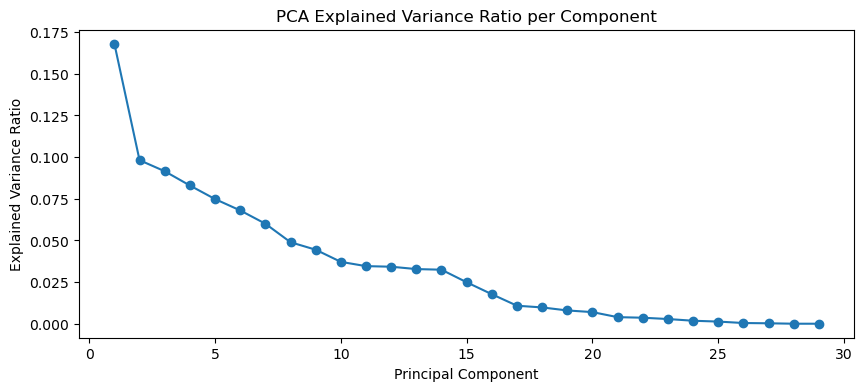

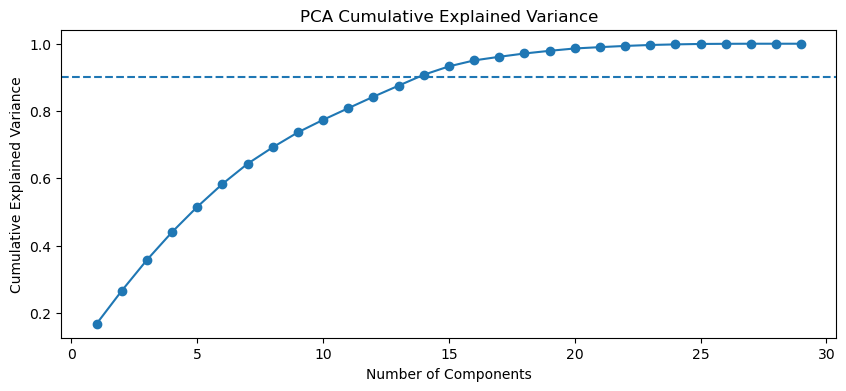

X_pca shape: (993, 14)


In [20]:
# =========================
# 4) Scale features + PCA
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit PCA (full) to inspect explained variance
pca_full = PCA(random_state=42)
X_pca_full = pca_full.fit_transform(X_scaled)

explained = pca_full.explained_variance_ratio_
cum_explained = np.cumsum(explained)

# Choose #components to retain ~90% (can adjust to 95% if desired)
target_var = 0.90
n_components_90 = int(np.argmax(cum_explained >= target_var) + 1)

print(f"PCA components to retain {int(target_var*100)}% variance: {n_components_90}")
print(f"Cumulative variance at {n_components_90} comps: {cum_explained[n_components_90-1]:.3f}")

# Plot explained variance and cumulative variance
plt.figure(figsize=(10,4))
plt.plot(range(1, len(explained)+1), explained, marker='o')
plt.title("PCA Explained Variance Ratio per Component")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.show()

plt.figure(figsize=(10,4))
plt.plot(range(1, len(cum_explained)+1), cum_explained, marker='o')
plt.axhline(target_var, linestyle='--')
plt.title("PCA Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.show()

# Fit PCA with selected components for clustering
pca = PCA(n_components=n_components_90, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("X_pca shape:", X_pca.shape)


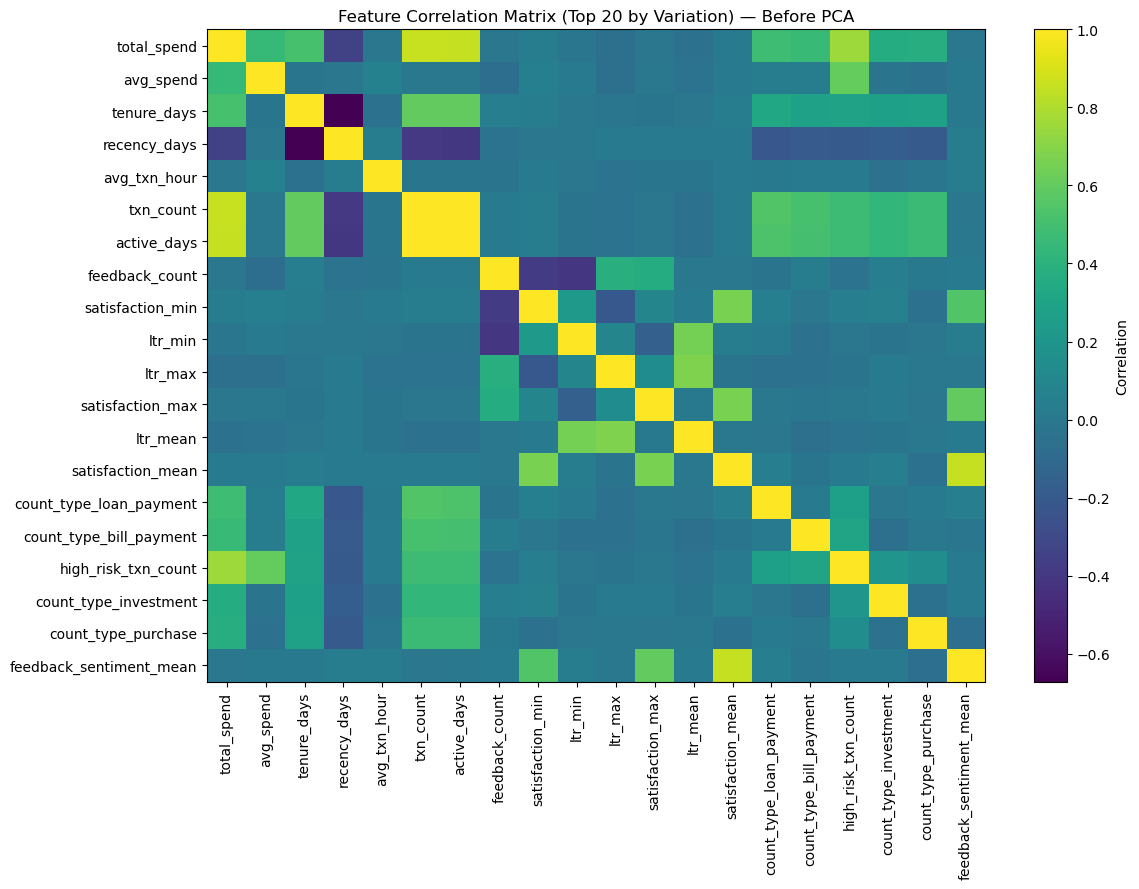

Top 10 absolute correlations (among top-variation features):


abs_corr
txn_count         active_days              0.994031
total_spend       txn_count                0.857769
                  active_days              0.854479
satisfaction_mean feedback_sentiment_mean  0.850798
total_spend       high_risk_txn_count      0.757555
ltr_max           ltr_mean                 0.675781
tenure_days       recency_days             0.671753
satisfaction_max  satisfaction_mean        0.666194
satisfaction_min  satisfaction_mean        0.665055
ltr_min           ltr_mean                 0.651909

In [21]:
# =========================
# 4A) Correlation Check (Final Selected Features - before PCA)
# =========================
# Goal: show multicollinearity among selected numeric features (reason PCA helps before K-Means)

# Use a readable subset: top features by standard deviation (highest variation)
stds = pd.Series(X.std(axis=0), index=feature_cols).sort_values(ascending=False)
top_corr_feats = stds.head(20).index.tolist()

corr_mat = pd.DataFrame(X_scaled, columns=feature_cols)[top_corr_feats].corr()

plt.figure(figsize=(12, 9))
plt.imshow(corr_mat.values, aspect="auto")
plt.colorbar(label="Correlation")
plt.title("Feature Correlation Matrix (Top 20 by Variation) — Before PCA")
plt.xticks(range(len(top_corr_feats)), top_corr_feats, rotation=90)
plt.yticks(range(len(top_corr_feats)), top_corr_feats)
plt.tight_layout()
plt.show()

# Quick look: top absolute correlations (excluding self-correlation)
corr_pairs = (
    corr_mat.abs()
    .where(np.triu(np.ones(corr_mat.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
    .head(10)
)
print("Top 10 absolute correlations (among top-variation features):")
display(corr_pairs.to_frame("abs_corr"))

## 5. Clustering Methodology

### 5.1 Algorithm Selection (Why K-Means)

We use **K-Means** as the primary clustering algorithm because:

- Our feature set is **numeric, standardized**, and appropriate for distance-based clustering  
- The EDA suggests customers form **broad, behavior-based groups** (value, frequency, timing, footprint) that K-Means can capture well  
- K-Means is **interpretable**: we can profile clusters via feature means/medians and easily communicate differences to stakeholders  
- It scales efficiently to customer-level datasets

We still validate our choice through **parameter tuning** and quality metrics (elbow + silhouette + Davies–Bouldin).


### 5.2 Parameter Tuning (Choosing the Number of Clusters)

We test multiple values of **k** and compare:
- **Inertia (Elbow Method):** measures within-cluster compactness  
- **Silhouette Score:** measures separation vs cohesion (higher is better)  
- **Davies–Bouldin Index:** measures cluster overlap (lower is better)

We choose the final **k** where:
- inertia improvement starts to diminish (elbow),
- silhouette is reasonably high,
- Davies–Bouldin is low.


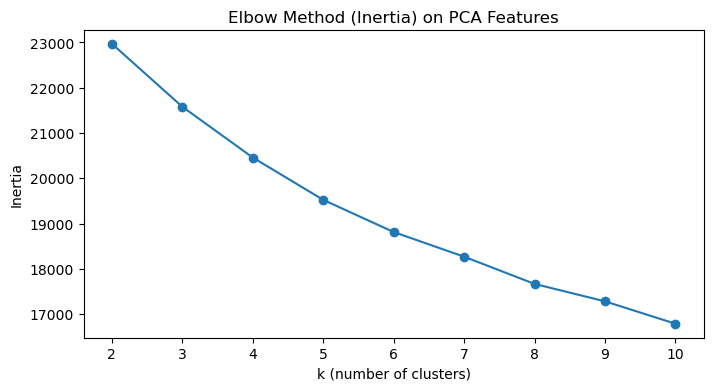

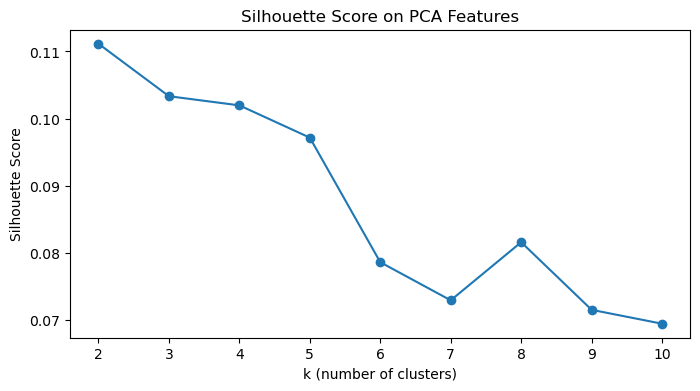

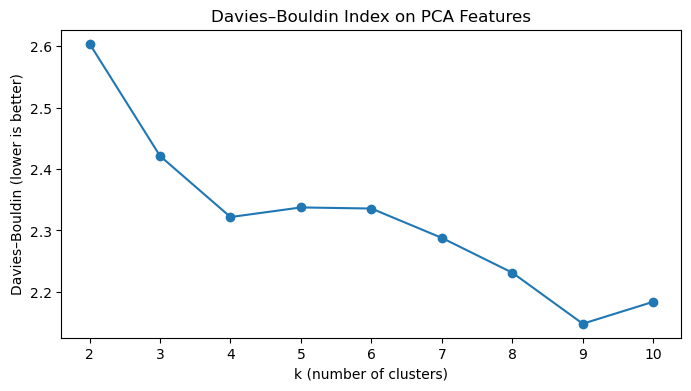

,k,inertia,silhouette,davies_bouldin
0,2,22971.065306,0.111148,2.604339
1,3,21579.748578,0.103331,2.421400
2,4,20457.736506,0.101967,2.321811
3,5,19523.019340,0.097162,2.337486
4,6,18811.834301,0.078607,2.335712
5,7,18267.224913,0.072933,2.287845
6,8,17666.100448,0.081589,2.231146
7,9,17280.734858,0.071517,2.147951
8,10,16786.701156,0.069447,2.183663


In [22]:
# =========================
# 5.2) K selection: elbow + silhouette + DB index
# =========================
k_range = range(2, 11)

inertias = []
sil_scores = []
db_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca, labels))
    db_scores.append(davies_bouldin_score(X_pca, labels))

# Plot inertia (elbow)
plt.figure(figsize=(8,4))
plt.plot(list(k_range), inertias, marker='o')
plt.title("Elbow Method (Inertia) on PCA Features")
plt.xlabel("k (number of clusters)")
plt.ylabel("Inertia")
plt.show()

# Plot silhouette
plt.figure(figsize=(8,4))
plt.plot(list(k_range), sil_scores, marker='o')
plt.title("Silhouette Score on PCA Features")
plt.xlabel("k (number of clusters)")
plt.ylabel("Silhouette Score")
plt.show()

# Plot Davies–Bouldin
plt.figure(figsize=(8,4))
plt.plot(list(k_range), db_scores, marker='o')
plt.title("Davies–Bouldin Index on PCA Features")
plt.xlabel("k (number of clusters)")
plt.ylabel("Davies–Bouldin (lower is better)")
plt.show()

metrics_df = pd.DataFrame({
    "k": list(k_range),
    "inertia": inertias,
    "silhouette": sil_scores,
    "davies_bouldin": db_scores
}).sort_values("k")

display(metrics_df)


In [23]:
# =========================
# 5.2A) Metrics summary + business-k justification helpers
# =========================

from sklearn.metrics import calinski_harabasz_score

# Compute CH index for each k (adds a third validation metric)
# X_pca should already exist at this point
ch_scores = []
for k in metrics_df["k"].tolist():
    km_tmp = KMeans(n_clusters=int(k), random_state=42, n_init=10)
    labels_tmp = km_tmp.fit_predict(X_pca)
    ch_scores.append(calinski_harabasz_score(X_pca, labels_tmp))

metrics_df = metrics_df.copy()
metrics_df["calinski_harabasz"] = ch_scores

# Sort view: best silhouette, then best DB, then best CH
display(metrics_df.sort_values(["silhouette", "davies_bouldin", "calinski_harabasz"],
                               ascending=[False, True, False]).reset_index(drop=True))

# Quick delta view for business options (3–4)
BUSINESS_K_OPTIONS = [3, 4]
biz_metrics = metrics_df[metrics_df["k"].isin(BUSINESS_K_OPTIONS)].copy()

print("Business k options evaluated:", BUSINESS_K_OPTIONS)
display(biz_metrics)

# Show relative differences (helps defend "metrics are close, choose interpretable k")
if len(biz_metrics) == 2:
    k3 = biz_metrics[biz_metrics["k"] == 3].iloc[0]
    k4 = biz_metrics[biz_metrics["k"] == 4].iloc[0]
    print("\nMetric comparison (k=3 vs k=4):")
    print(f"Silhouette: k=3 {k3['silhouette']:.4f} | k=4 {k4['silhouette']:.4f} | Δ={k3['silhouette']-k4['silhouette']:+.4f}")
    print(f"Davies-Bouldin: k=3 {k3['davies_bouldin']:.4f} | k=4 {k4['davies_bouldin']:.4f} | Δ={k3['davies_bouldin']-k4['davies_bouldin']:+.4f} (lower is better)")
    print(f"Calinski-Harabasz: k=3 {k3['calinski_harabasz']:.2f} | k=4 {k4['calinski_harabasz']:.2f} | Δ={k3['calinski_harabasz']-k4['calinski_harabasz']:+.2f}")

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,22971.065306,0.111148,2.604339,136.782890
1,3,21579.748578,0.103331,2.421400,104.637099
2,4,20457.736506,0.101967,2.321811,91.590335
3,5,19523.019340,0.097162,2.337486,83.734610
4,8,17666.100448,0.081589,2.231146,67.507982
5,6,18811.834301,0.078607,2.335712,76.912552
6,7,18267.224913,0.072933,2.287845,70.837125
7,9,17280.734858,0.071517,2.147951,63.068382
8,10,16786.701156,0.069447,2.183663,60.866424


Business k options evaluated: [3, 4]


,k,inertia,silhouette,davies_bouldin,calinski_harabasz
1,3,21579.748578,0.103331,2.421400,104.637099
2,4,20457.736506,0.101967,2.321811,91.590335



Metric comparison (k=3 vs k=4):
Silhouette: k=3 0.1033 | k=4 0.1020 | Δ=+0.0014
Davies-Bouldin: k=3 2.4214 | k=4 2.3218 | Δ=+0.0996 (lower is better)
Calinski-Harabasz: k=3 104.64 | k=4 91.59 | Δ=+13.05


### 5.3 Final Choice of *k* (Metrics + Business Interpretability)

Even though **k=2** gives the highest *global* silhouette score, it often produces segments that are **too broad** (e.g., “high vs low”) and **less actionable** for business teams.  
For this milestone, our goal is to produce **meaningful and explainable customer segments** that can map to real strategies (retention, upsell, win‑back, service recovery).

**How we defend the “business‑k” approach**
- **Step 1 — Compute clustering quality metrics** across a range of *k* values:
  - **Silhouette** (higher is better): separation / cohesion
  - **Davies–Bouldin** (lower is better): compactness / overlap
  - **Calinski–Harabasz** (higher is better): cluster separation
- **Step 2 — Compare only the business‑reasonable candidates** (here: **k ∈ {3, 4}**) because:
  - 3–4 segments are **easy to communicate** to stakeholders
  - 3–4 segments are **operationally actionable** (campaigns, offers, service policies)
  - higher *k* can create **micro‑segments** that are hard to justify and maintain
- **Step 3 — Pick the final *k*** using metrics **plus** interpretability:
  - If metrics are **very close**, we select the *k* that yields **richer, more actionable** segmentation
  - We also run a **bootstrap stability check** (silhouette mean/std) to show the solution is not overly sensitive to sampling

✅ **Final decision:** We proceed with **k = 4**, because it provides *more actionable segmentation* than k=3 **while keeping metrics competitive** (only small changes in silhouette) and producing clearer business personas.


In [24]:
# =========================
# 5.3) Final k selection (metrics + business interpretability)
# =========================

FORCE_BUSINESS_K = True
PREFERRED_BUSINESS_K = 4  # if ties/near-ties, 4 can yield richer segmentation

biz_metrics = metrics_df[metrics_df["k"].isin(BUSINESS_K_OPTIONS)].copy()

# Define what "close enough" means for silhouette (so we can justify preferring interpretability)
SIL_CLOSE_THRESHOLD = 0.01  # treat differences < 0.01 as practically small in many real datasets

if biz_metrics.empty:
    K_FINAL = int(metrics_df.sort_values(["silhouette", "davies_bouldin"], ascending=[False, True]).iloc[0]["k"])
    reason = "Business options were not available in the evaluated k range; selected best overall by metrics."
else:
    # Rank business options: silhouette (primary), DB (secondary), CH (tertiary)
    biz_ranked = biz_metrics.sort_values(
        ["silhouette", "davies_bouldin", "calinski_harabasz"],
        ascending=[False, True, False]
    ).reset_index(drop=True)

    best_biz = biz_ranked.iloc[0]
    K_FINAL = int(best_biz["k"])

    # If top two are extremely close in silhouette, choose the preferred business k (if it exists)
    if len(biz_ranked) > 1:
        second_biz = biz_ranked.iloc[1]
        sil_gap = float(best_biz["silhouette"] - second_biz["silhouette"])

        if abs(sil_gap) < SIL_CLOSE_THRESHOLD and PREFERRED_BUSINESS_K in biz_metrics["k"].values:
            K_FINAL = int(PREFERRED_BUSINESS_K)
            reason = (
                f"Business-k selection: k options {BUSINESS_K_OPTIONS} are very close in silhouette "
                f"(gap={sil_gap:+.4f} < {SIL_CLOSE_THRESHOLD}). Chose k={K_FINAL} for richer, more actionable segmentation."
            )
        else:
            reason = (
                f"Business-k selection: selected k={K_FINAL} because it ranks best within {BUSINESS_K_OPTIONS} "
                f"using silhouette (primary), Davies–Bouldin (secondary), and Calinski–Harabasz (tertiary)."
            )
    else:
        reason = f"Business-k selection: only one business option available; selected k={K_FINAL}."

# Also compute and print global best (for transparency)
global_best = metrics_df.sort_values(["silhouette", "davies_bouldin", "calinski_harabasz"],
                                    ascending=[False, True, False]).iloc[0]
global_k = int(global_best["k"])

print(f"Global best by metrics -> k={global_k} (sil={global_best['silhouette']:.4f}, DB={global_best['davies_bouldin']:.4f}, CH={global_best['calinski_harabasz']:.2f})")
print(f"Selected k (final) -> k={K_FINAL}")
print("Justification:", reason)

Global best by metrics -> k=2 (sil=0.1111, DB=2.6043, CH=136.78)
Selected k (final) -> k=4
Justification: Business-k selection: k options [3, 4] are very close in silhouette (gap=+0.0014 < 0.01). Chose k=4 for richer, more actionable segmentation.


In [25]:
# =========================
# 5.3A) Stability check (bootstrapped silhouette for k=3 vs k=4)
# =========================

import numpy as np

def bootstrap_silhouette(X, k, n_boot=25, sample_frac=0.85, seed=42):
    rng = np.random.default_rng(seed)
    scores = []
    n = X.shape[0]
    m = int(n * sample_frac)

    for _ in range(n_boot):
        idx = rng.choice(n, size=m, replace=True)
        Xb = X[idx]
        km = KMeans(n_clusters=k, random_state=seed, n_init=10)
        labels = km.fit_predict(Xb)
        s = silhouette_score(Xb, labels)
        scores.append(s)
    return np.array(scores)

for k_test in [3, 4]:
    scores = bootstrap_silhouette(X_pca, k_test, n_boot=25, sample_frac=0.85, seed=42)
    print(f"k={k_test} bootstrap silhouette: mean={scores.mean():.4f} | std={scores.std():.4f} | min={scores.min():.4f} | max={scores.max():.4f}")

k=3 bootstrap silhouette: mean=0.1068 | std=0.0050 | min=0.0985 | max=0.1179
k=4 bootstrap silhouette: mean=0.1025 | std=0.0076 | min=0.0867 | max=0.1164


## 6. Run K-Means Clustering (on PCA Features)

We fit K-Means using the PCA-reduced feature space and assign a cluster label to each customer.


In [26]:
# =========================
# 6) Fit final K-Means
# =========================
kmeans = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_pca)

df_clusters = df.copy()
df_clusters["cluster"] = cluster_labels

print("Cluster counts:")
display(df_clusters["cluster"].value_counts().sort_index().to_frame("count"))

print("\nSilhouette (final):", round(silhouette_score(X_pca, cluster_labels), 3))
print("Davies–Bouldin (final):", round(davies_bouldin_score(X_pca, cluster_labels), 3))


Cluster counts:


,count
cluster,
0,165
1,292
2,127
3,409



Silhouette (final): 0.102
Davies–Bouldin (final): 2.322


## 7. Visualizing the Clusters (PCA Space)

To interpret how well clusters separate, we project customers into the first two principal components (PC1 & PC2) and color points by cluster label.

> Note: PCA axes do not correspond to a single original feature; each PC is a weighted combination of multiple behaviors.


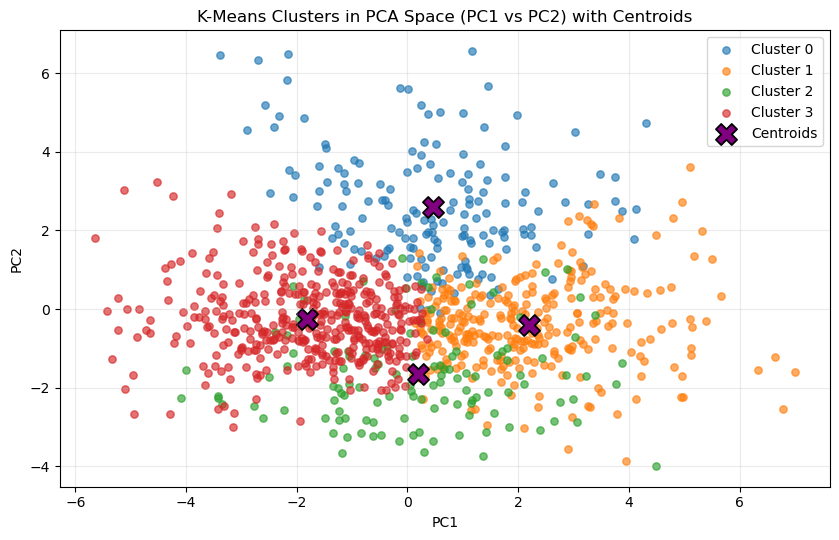


PCA CLUSTER VIEW — INTERPRETATION SUMMARY

CLUSTER 0: 165 customers (16.6%)
Key Characteristics:
  • total_spend: 13,211.25 (+641.53 vs overall 12,569.72)
  • txn_count: 5.19 (+0.15 vs overall 5.04)
  • recency_days: 34.87 (-3.85 vs overall 38.72)  [lower = more recent]
  • satisfaction_mean: 7.32 (+1.72 vs overall 5.60)

CLUSTER 1: 292 customers (29.4%)
Key Characteristics:
  • total_spend: 18,966.70 (+6,396.98 vs overall 12,569.72)
  • txn_count: 7.15 (+2.11 vs overall 5.04)
  • recency_days: 23.02 (-15.70 vs overall 38.72)  [lower = more recent]
  • satisfaction_mean: 5.58 (-0.02 vs overall 5.60)

CLUSTER 2: 127 customers (12.8%)
Key Characteristics:
  • total_spend: 12,984.10 (+414.38 vs overall 12,569.72)
  • txn_count: 5.19 (+0.15 vs overall 5.04)
  • recency_days: 35.51 (-3.20 vs overall 38.72)  [lower = more recent]
  • satisfaction_mean: 3.51 (-2.09 vs overall 5.60)

CLUSTER 3: 409 customers (41.2%)
Key Characteristics:
  • total_spend: 7,615.21 (-4,954.51 vs overall 12,569.7

In [27]:
# -----------------------------
# 7A) K-Means clusters in PCA space (PC1 vs PC2) + Centroids + Insights
# -----------------------------

# Pick the correct trained KMeans object (handles variable-name differences)
kmeans_obj = None
for _name in ["kmeans_final", "kmeans", "kmeans_model"]:
    if _name in globals():
        kmeans_obj = globals()[_name]
        break

if kmeans_obj is None:
    raise NameError("No trained KMeans model found. Expected one of: kmeans_final, kmeans, kmeans_model.")

# Build a consistent color map for clusters (used across plots)
cmap = plt.get_cmap("tab10")
cluster_ids_sorted = sorted(pd.Series(cluster_labels).unique())
cluster_colors = {cl: cmap(int(cl) % 10) for cl in cluster_ids_sorted}

# Ensure df_pca exists in this cell
df_pca = pd.DataFrame(X_pca[:, :2], columns=["PC1", "PC2"])
df_pca["cluster"] = cluster_labels

plt.figure(figsize=(8.5, 5.5))

for cl in cluster_ids_sorted:
    sub = df_pca[df_pca["cluster"] == cl]
    plt.scatter(
        sub["PC1"], sub["PC2"],
        alpha=0.65, s=28,
        label=f"Cluster {cl}",
        color=cluster_colors[cl]
    )

# Centroids are in PCA-space because KMeans was trained on X_pca
centroids_pca = kmeans_obj.cluster_centers_[:, :2]
plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    marker="X", s=230,
    edgecolors="k", linewidths=1.3,
    color="purple",
    label="Centroids"
)

plt.title("K-Means Clusters in PCA Space (PC1 vs PC2) with Centroids")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# -----------------------------
# Printed insights (PCA view)
# -----------------------------
print("\n" + "="*92)
print("PCA CLUSTER VIEW — INTERPRETATION SUMMARY")
print("="*92)

n_total = len(df_clusters)
cluster_counts = df_clusters["cluster"].value_counts().sort_index()

# Use the same “core” columns you’re already using in other interpretation blocks
# (safe picks; will only use columns that exist)
def _pick_existing(cols, df):
    for c in cols:
        if c in df.columns:
            return c
    return None

money_col = _pick_existing(["total_spend", "Total_Spend", "monetary", "monetary_value"], df_clusters)
freq_col  = _pick_existing(["txn_count", "Transaction_Count", "frequency", "freq"], df_clusters)
rec_col   = _pick_existing(["recency_days", "Recency_Days", "recency"], df_clusters)
sat_col   = _pick_existing(["satisfaction_mean", "Satisfaction_Mean", "satisfaction_score", "satisfaction"], df_clusters)

core_cols = [c for c in [money_col, freq_col, rec_col, sat_col] if c]
overall_means = df_clusters[core_cols].mean(numeric_only=True) if core_cols else pd.Series(dtype=float)

for cl in cluster_counts.index:
    n = int(cluster_counts.loc[cl])
    pct = (n / n_total) * 100

    print("\n" + "="*60)
    print(f"CLUSTER {cl}: {n} customers ({pct:.1f}%)")
    print("="*60)

    if not core_cols:
        print("Key Characteristics: (No core columns found to summarize.)")
        continue

    cl_means = df_clusters.loc[df_clusters["cluster"] == cl, core_cols].mean(numeric_only=True)

    print("Key Characteristics:")
    for c in core_cols:
        v = float(cl_means[c])
        o = float(overall_means[c])
        delta = v - o

        # Formatting based on common meaning
        if c == rec_col:
            # recency: lower is better (more recent)
            print(f"  • {c}: {v:,.2f} ({delta:+,.2f} vs overall {o:,.2f})  [lower = more recent]")
        else:
            print(f"  • {c}: {v:,.2f} ({delta:+,.2f} vs overall {o:,.2f})")

print("\nNote: PCA plot shows how clusters separate in reduced 2D space; insights above explain them in business metrics.")

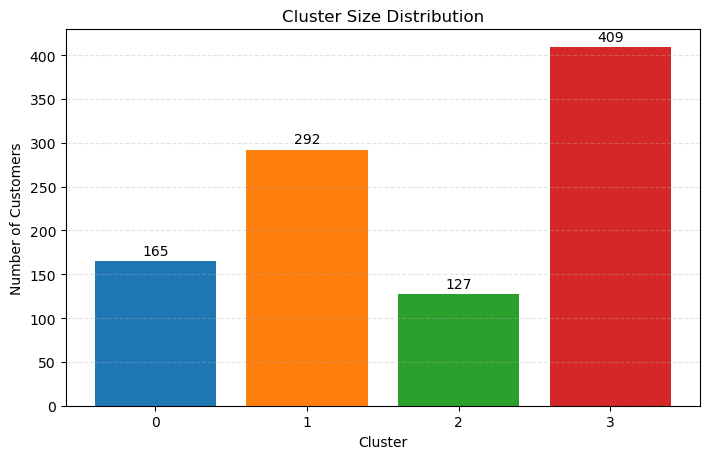


CLUSTER SIZE DISTRIBUTION
Cluster 0: 165 customers (16.6%)
Cluster 1: 292 customers (29.4%)
Cluster 2: 127 customers (12.8%)
Cluster 3: 409 customers (41.2%)


In [28]:
# =========================
# 7B) Cluster size distribution (visual)
# =========================
cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()

# Use the same cluster_colors from the PCA plot (fallback to tab10 if needed)
if "cluster_colors" not in globals():
    cmap = plt.get_cmap("tab10")
    cluster_colors = {cl: cmap(int(cl) % 10) for cl in sorted(cluster_counts.index.tolist())}

bar_colors = [cluster_colors[int(cl)] for cl in cluster_counts.index]

plt.figure(figsize=(7.2, 4.7))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values, color=bar_colors)
plt.title("Cluster Size Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

# Data labels
for i, v in enumerate(cluster_counts.values):
    plt.text(i, v + max(cluster_counts.values)*0.01, str(int(v)), ha="center", va="bottom")

plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# Print a quick cluster distribution summary
total_n = int(cluster_counts.sum())
print("\n" + "="*60)
print("CLUSTER SIZE DISTRIBUTION")
print("="*60)
for cl, n in cluster_counts.items():
    pct = (n / total_n * 100)
    print(f"Cluster {cl}: {int(n)} customers ({pct:.1f}%)")


## 8. Cluster Analysis and Initial Interpretation

### 8.1 Cluster Profiles (Descriptive Statistics)

We describe clusters using:
- **Size** of each cluster
- **Means / medians** of key behavioral features (spend, frequency, timing, transaction mix, tenure/recency, satisfaction)
- **Top differentiators**: features where a cluster is most above/below the dataset average


In [29]:
# =========================
# 8) Cluster profiling
# =========================

# Cluster sizes
cluster_sizes = df_clusters["cluster"].value_counts().sort_index()
cluster_sizes.name = "count"

# Mean profiles (numeric features)
cluster_means = df_clusters.groupby("cluster")[feature_cols].mean()
cluster_medians = df_clusters.groupby("cluster")[feature_cols].median()

# Add size to profile table
profiles = cluster_means.copy()
profiles.insert(0, "cluster_size", cluster_sizes)

display(profiles.head())

print("\nCluster size distribution:")
display(cluster_sizes.to_frame())

# Optional: income tier distribution per cluster (if available)
if income_group_col:
    print("\nIncome tier distribution by cluster:")
    tier_by_cluster = pd.crosstab(df_clusters["cluster"], df_clusters[income_group_col], normalize="index") * 100
    display(tier_by_cluster.round(1))


,cluster_size,total_spend,avg_spend,txn_count,active_days,tenure_days,recency_days,pct_weekend_txn,pct_business_hours_txn,avg_txn_hour,count_type_bill_payment,count_type_investment,count_type_loan_payment,count_type_purchase,pct_tod_Afternoon,pct_tod_Evening,pct_tod_Morning,pct_tod_Night,high_risk_txn_count,pct_high_risk_txn,feedback_count,satisfaction_mean,satisfaction_std,satisfaction_min,satisfaction_max,ltr_mean,ltr_std,ltr_min,ltr_max,feedback_sentiment_mean
cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,165,13211.248485,2630.502424,5.187879,5.145455,137.739394,34.866667,0.279212,0.365758,12.062121,1.278788,1.412121,1.442424,1.054545,0.240848,0.182545,0.259273,0.317455,1.400000,0.299091,3.769697,7.323636,1.704848,5.478788,9.012121,5.546606,2.106061,3.369697,7.751515,4.163636
1,292,18966.702055,2707.031473,7.147260,7.054795,158.575342,23.020548,0.275068,0.325925,11.322534,1.821918,1.702055,1.866438,1.756849,0.193664,0.163219,0.310411,0.331952,2.143836,0.318253,5.660959,5.577192,3.012089,2.013699,9.106164,5.419726,2.774178,2.099315,8.756849,2.986301
2,127,12984.102362,2521.316929,5.188976,5.110236,135.362205,35.511811,0.279449,0.356772,11.820709,1.196850,1.362205,1.291339,1.338583,0.241496,0.172913,0.256378,0.329370,1.283465,0.256063,3.818898,3.507559,1.697953,1.850394,5.370079,5.739685,2.383228,3.228346,8.204724,1.393701
3,409,7615.206601,2287.533423,3.418093,3.388753,101.166259,52.469438,0.285208,0.318044,11.354817,0.845966,0.831296,0.811736,0.929095,0.191125,0.149267,0.306015,0.352787,0.567237,0.186479,5.513447,5.567604,3.005232,1.970660,9.063570,5.631491,2.776284,2.283619,8.865526,3.053790



Cluster size distribution:


,count
cluster,
0,165
1,292
2,127
3,409



Income tier distribution by cluster:


Income_Group,High,Low,Medium
cluster,,,
0,20.6,9.7,69.7
1,62.7,0.3,37.0
2,24.4,15.7,59.8
3,0.0,51.8,48.2


Key features to visualize: ['total_spend', 'txn_count', 'recency_days', 'tenure_days', 'avg_spend', 'satisfaction_mean', 'pct_business_hours_txn', 'pct_weekend_txn', 'avg_txn_hour', 'count_type_loan_payment', 'count_type_investment', 'count_type_bill_payment', 'count_type_purchase']


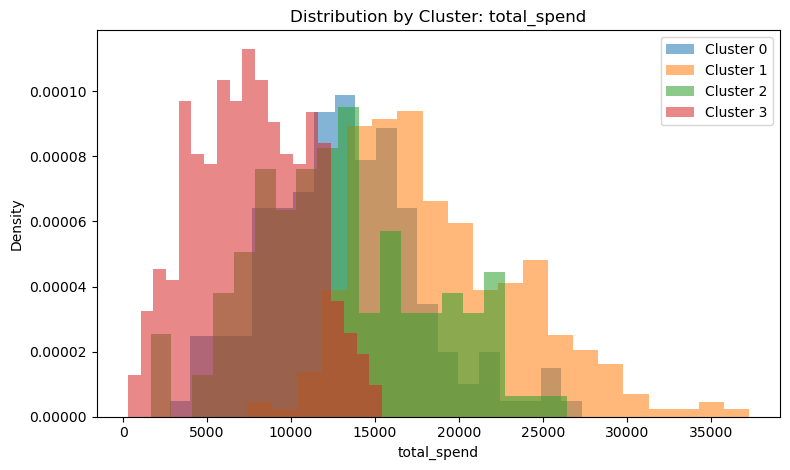

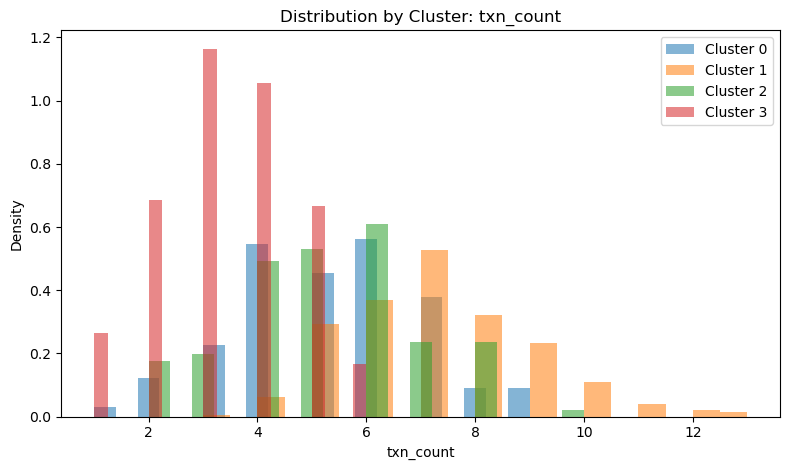

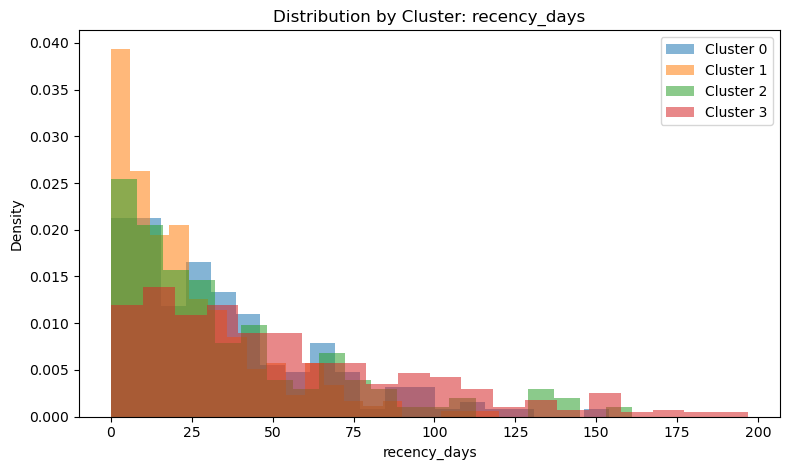

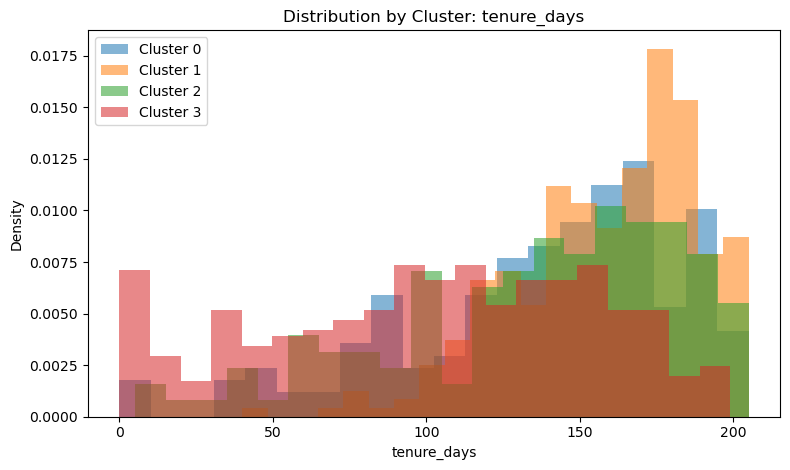

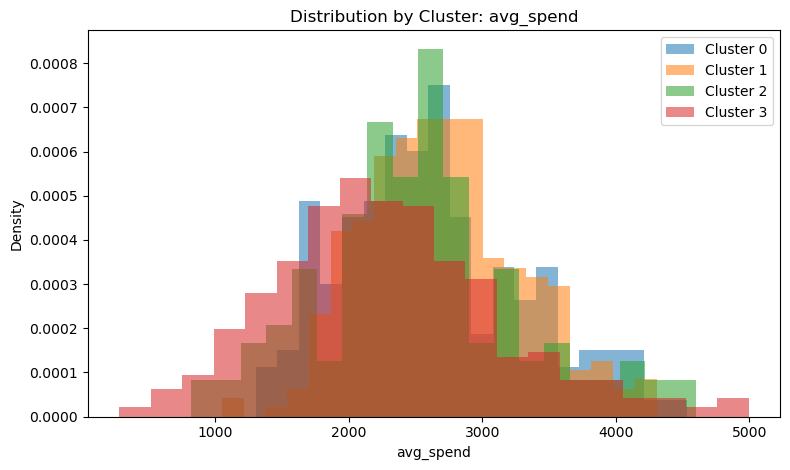

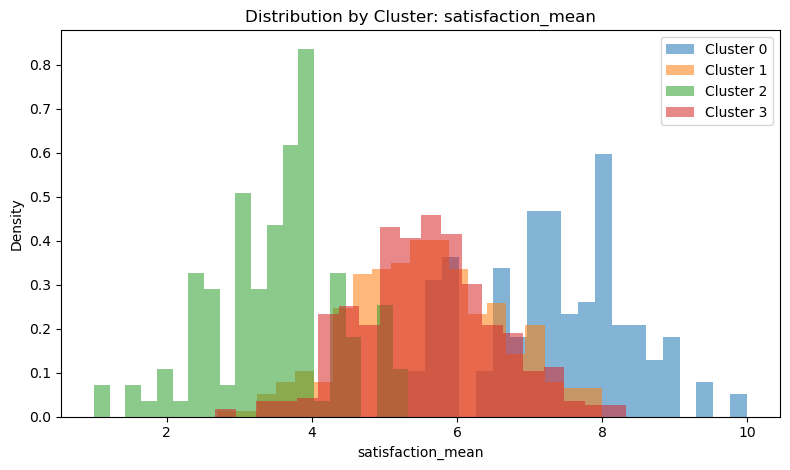

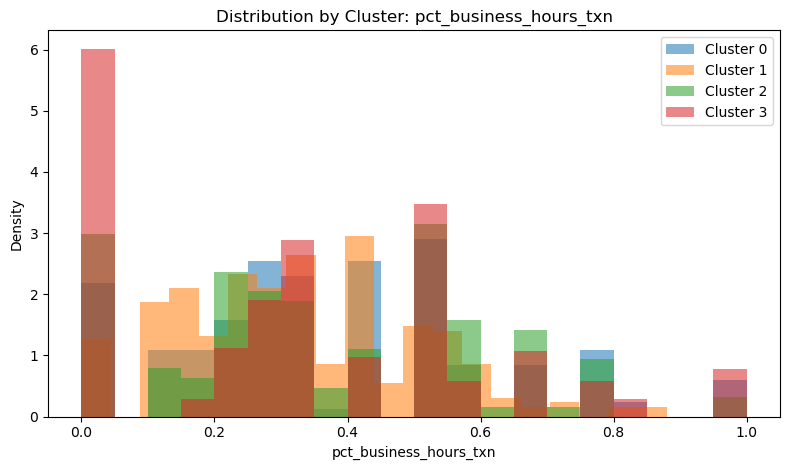

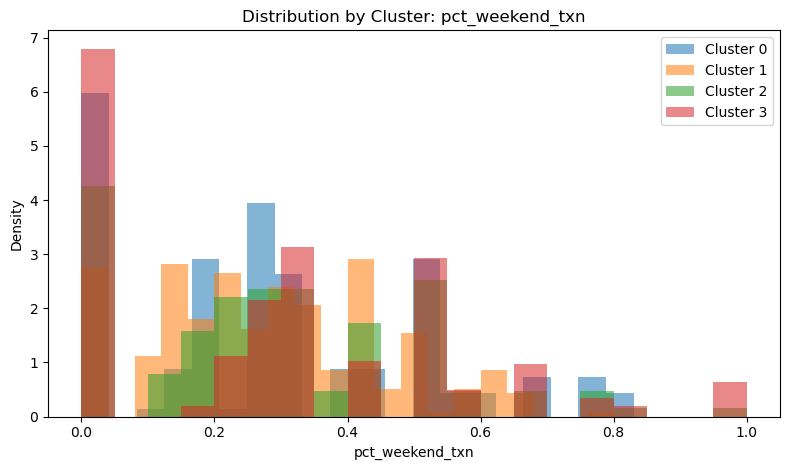

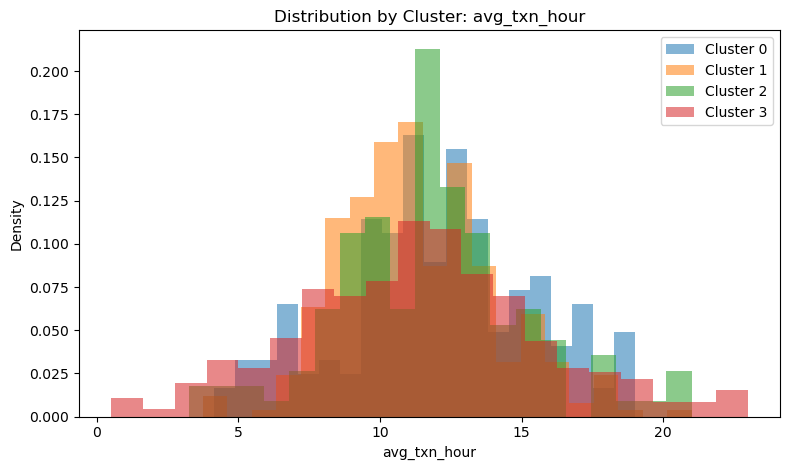

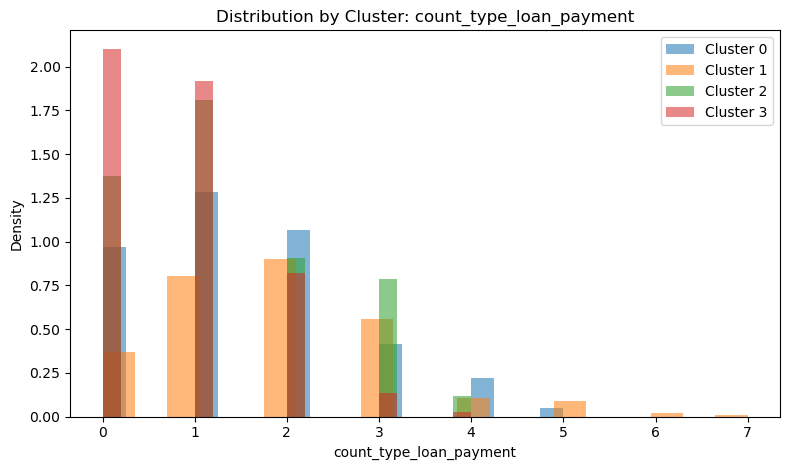

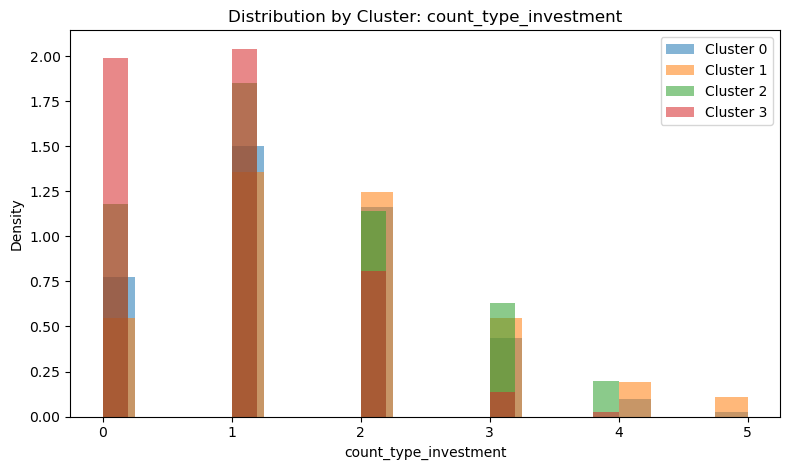

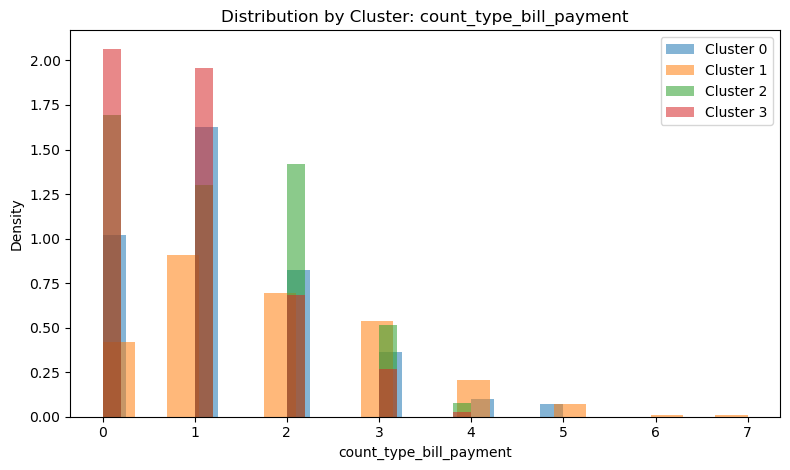

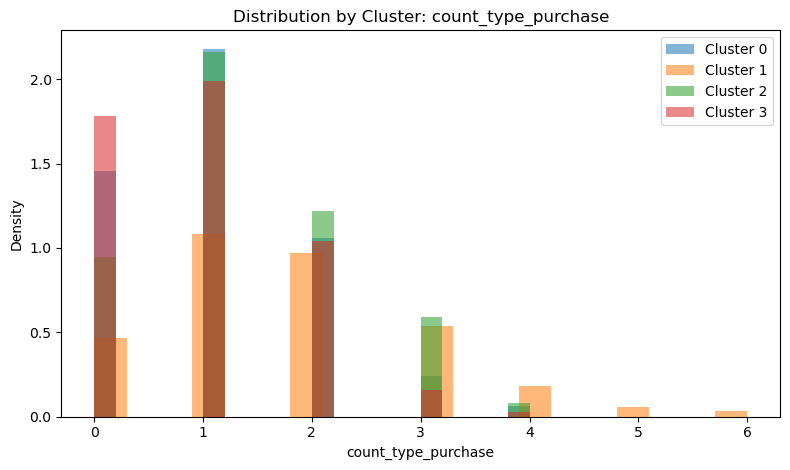

total_spend                    txn_count               recency_days                tenure_days                avg_spend            \
               mean   median       std      mean median    std         mean median     std        mean median     std      mean    median   
cluster                                                                                                                                     
0         13211.248  13363.0  4598.522     5.188    5.0  1.713       34.867   28.0  29.761     137.739  148.0  44.442  2630.502  2541.500   
1         18966.702  17789.0  5043.991     7.147    7.0  1.746       23.021   17.0  22.196     158.575  165.5  29.445  2707.031  2675.085   
2         12984.102  12508.0  5259.604     5.189    5.0  1.675       35.512   25.0  34.579     135.362  145.0  47.133  2521.317  2499.400   
3          7615.207   7678.5  3324.873     3.418    3.0  1.252       52.469   41.0  42.061     101.166  105.0  53.550  2287.533  2225.330   

                 satisfaction_mean               pct_business_hours_txn               pct_weekend_txn               avg_txn_hour         \
             std              mean median    std                   mean median    std            mean median    std         mean median   
cluster                                                                                                                                   
0        686.634             7.324   7.33  1.026                  0.366   0.33  0.235           0.279   0.25  0.222       12.062  11.88   
1        588.903             5.577   5.57  1.004                  0.326   0.33  0.177           0.275   0.25  0.172       11.323  11.04   
2        764.840             3.508   3.67  0.878                  0.357   0.33  0.237           0.279   0.25  0.212       11.821  11.67   
3        834.925             5.568   5.50  0.949                  0.318   0.33  0.273           0.285   0.25  0.262       11.355  11.25   

               count_type_loan_payment               count_type_investment               count_type_bill_payment                \
           std                    mean median    std                  mean median    std                    mean median    std   
cluster                                                                                                                          
0        3.373                   1.442    1.0  1.191                 1.412    1.0  1.036                   1.279    1.0  1.124   
1        2.723                   1.866    2.0  1.268                 1.702    2.0  1.174                   1.822    2.0  1.309   
2        3.356                   1.291    1.0  1.106                 1.362    1.0  1.096                   1.197    1.0  1.069   
3        4.303                   0.812    1.0  0.838                 0.831    1.0  0.827                   0.846    1.0  0.887   

        count_type_purchase                
                       mean median    std  
cluster                                    
0                     1.055    1.0  0.899  
1                     1.757    2.0  1.238  
2                     1.339    1.0  0.970  
3                     0.929    1.0  0.856

In [30]:
# ===========================
# 8B) Cluster separation on key business features
# ===========================
# We visualize distributions by cluster for the most interpretable variables.
# This version avoids NameError by auto-detecting the correct column names.

import numpy as np
import matplotlib.pyplot as plt

# --- Helper: pick the first existing column name from candidates
def pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

# --- Resolve key columns robustly (handles minor naming differences)
total_spend_col  = pick_col(df_clusters, ["total_spend", "Total_Spend", "totalSpend"])
txn_count_col    = pick_col(df_clusters, ["txn_count", "txns_count", "transaction_count", "Transaction_Count"])
recency_col      = pick_col(df_clusters, ["recency_days", "recency", "days_since_last_txn", "Recency_Days"])
tenure_col       = pick_col(df_clusters, ["tenure_days", "tenure", "customer_tenure_days", "Tenure_Days"])
avg_spend_col    = pick_col(df_clusters, ["avg_spend", "avg_txn_amount", "average_spend", "Avg_Spend"])
satisfaction_col = pick_col(df_clusters, ["satisfaction_mean", "avg_satisfaction", "satisfaction", "Satisfaction_Mean"])

# --- Build a "preferred" list, but only keep what exists
preferred = [
    total_spend_col,
    txn_count_col,
    recency_col,
    tenure_col,
    avg_spend_col,
    satisfaction_col,
    "pct_business_hours_txn",
    "pct_weekend_txn",
    "avg_txn_hour",
    "count_type_loan_payment",
    "count_type_investment",
    "count_type_bill_payment",
    "count_type_purchase",
]

# Remove Nones and keep only existing cols
key_features = [c for c in preferred if c and c in df_clusters.columns]

# Fallback: if something goes wrong and list becomes too small, pick top-8 numeric cols (excluding ids/cluster)
if len(key_features) < 5:
    numeric_cols = df_clusters.select_dtypes(include=[np.number]).columns.tolist()
    fallback = [c for c in numeric_cols if c not in ["cluster", "cluster_name"]]
    key_features = fallback[:8]

print("Key features to visualize:", key_features)

# --- Plot: per-feature distribution by cluster
for feat in key_features:
    plt.figure(figsize=(8, 4.8))
    for cl in sorted(df_clusters["cluster"].unique()):
        vals = df_clusters.loc[df_clusters["cluster"] == cl, feat].dropna().values
        plt.hist(vals, bins=20, alpha=0.55, density=True, label=f"Cluster {cl}")

    plt.title(f"Distribution by Cluster: {feat}")
    plt.xlabel(feat)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Optional: quick numeric summary table per cluster for these features
display(
    df_clusters.groupby("cluster")[key_features]
    .agg(["mean", "median", "std"])
    .round(3)
)

### 8C) Customer Segmentation Views (RFM-style + Experience)

To make the clusters more interpretable for business stakeholders, we also visualize **Recency vs Frequency** (RFM-style) and **Monetary vs Satisfaction**.


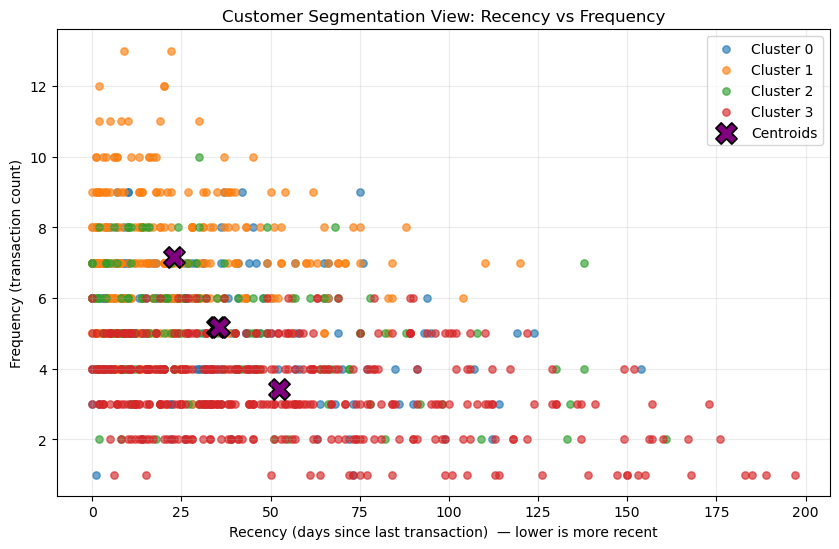


RECENCY vs FREQUENCY (Interpretation)

CLUSTER 0: 165 customers (16.6%)  |  Segment: Cluster 0
  • recency_days: 34.87  (-3.85 vs overall 38.72)
  • txn_count: 5.19  (+0.15 vs overall 5.04)

CLUSTER 1: 292 customers (29.4%)  |  Segment: Cluster 1
  • recency_days: 23.02  (-15.70 vs overall 38.72)
  • txn_count: 7.15  (+2.11 vs overall 5.04)

CLUSTER 2: 127 customers (12.8%)  |  Segment: Cluster 2
  • recency_days: 35.51  (-3.20 vs overall 38.72)
  • txn_count: 5.19  (+0.15 vs overall 5.04)

CLUSTER 3: 409 customers (41.2%)  |  Segment: Cluster 3
  • recency_days: 52.47  (+13.75 vs overall 38.72)
  • txn_count: 3.42  (-1.62 vs overall 5.04)


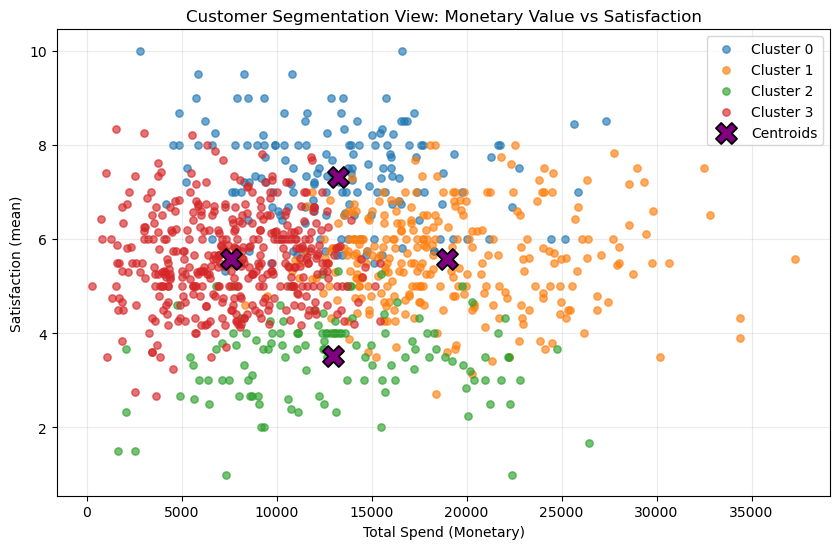


MONETARY vs SATISFACTION (Interpretation)

CLUSTER 0: 165 customers (16.6%)  |  Segment: Cluster 0
  • total_spend: 13,211.25  (+641.53 vs overall 12,569.72)
  • satisfaction_mean: 7.32  (+1.72 vs overall 5.60)

CLUSTER 1: 292 customers (29.4%)  |  Segment: Cluster 1
  • total_spend: 18,966.70  (+6396.98 vs overall 12,569.72)
  • satisfaction_mean: 5.58  (-0.02 vs overall 5.60)

CLUSTER 2: 127 customers (12.8%)  |  Segment: Cluster 2
  • total_spend: 12,984.10  (+414.38 vs overall 12,569.72)
  • satisfaction_mean: 3.51  (-2.09 vs overall 5.60)

CLUSTER 3: 409 customers (41.2%)  |  Segment: Cluster 3
  • total_spend: 7,615.21  (-4954.51 vs overall 12,569.72)
  • satisfaction_mean: 5.57  (-0.03 vs overall 5.60)


In [31]:
# =========================
# 8C) Business-friendly segmentation views (RFM-style)
# =========================
# We visualize cluster separation on interpretable axes:
#   A) Recency vs Frequency
#   B) Monetary vs Satisfaction

# Ensure we have consistent colors
if "cluster_colors" not in globals():
    cmap = plt.get_cmap("tab10")
    cluster_colors = {cl: cmap(int(cl) % 10) for cl in sorted(df_clusters["cluster"].unique())}

def print_axis_summary(title, x_col, y_col):
    print("\n" + "="*70)
    print(title)
    print("="*70)
    total_n = len(df_clusters)
    overall_x = df_clusters[x_col].mean()
    overall_y = df_clusters[y_col].mean()

    for cl in sorted(df_clusters["cluster"].unique()):
        sub = df_clusters[df_clusters["cluster"] == cl]
        n = len(sub)
        pct = n / total_n * 100
        seg = sub["cluster_name"].mode().iloc[0] if "cluster_name" in sub.columns else f"Cluster {cl}"

        cx = sub[x_col].mean()
        cy = sub[y_col].mean()

        print(f"\nCLUSTER {cl}: {n} customers ({pct:.1f}%)  |  Segment: {seg}")
        print(f"  • {x_col}: {cx:,.2f}  ({cx-overall_x:+.2f} vs overall {overall_x:,.2f})")
        print(f"  • {y_col}: {cy:,.2f}  ({cy-overall_y:+.2f} vs overall {overall_y:,.2f})")

# --- (A) Recency vs Frequency
recency_col = recency_days_col if "recency_days_col" in globals() else "recency_days"
freq_col = txn_count_col if "txn_count_col" in globals() else "txn_count"

if recency_col in df_clusters.columns and freq_col in df_clusters.columns:
    plt.figure(figsize=(8.5, 5.6))
    for cl in sorted(df_clusters["cluster"].unique()):
        sub = df_clusters[df_clusters["cluster"] == cl]
        plt.scatter(sub[recency_col], sub[freq_col],
                    alpha=0.65, s=28, label=f"Cluster {cl}",
                    color=cluster_colors[int(cl)])

    # Centroids in the original feature space for these axes
    cent = df_clusters.groupby("cluster")[[recency_col, freq_col]].mean()
    plt.scatter(cent[recency_col], cent[freq_col],
                marker="X", s=230, edgecolors="k", linewidths=1.3,
                color="purple", label="Centroids")

    plt.title("Customer Segmentation View: Recency vs Frequency")
    plt.xlabel("Recency (days since last transaction)  — lower is more recent")
    plt.ylabel("Frequency (transaction count)")
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print_axis_summary("RECENCY vs FREQUENCY (Interpretation)", recency_col, freq_col)
else:
    print("Recency–Frequency plot skipped (missing recency_days or txn_count columns).")

# --- (B) Monetary vs Satisfaction
money_col = total_spend_col if "total_spend_col" in globals() else "total_spend"
sat_col = satisfaction_col if "satisfaction_col" in globals() else "satisfaction_mean"

if money_col in df_clusters.columns and sat_col in df_clusters.columns:
    plt.figure(figsize=(8.5, 5.6))
    for cl in sorted(df_clusters["cluster"].unique()):
        sub = df_clusters[df_clusters["cluster"] == cl]
        plt.scatter(sub[money_col], sub[sat_col],
                    alpha=0.65, s=28, label=f"Cluster {cl}",
                    color=cluster_colors[int(cl)])

    cent2 = df_clusters.groupby("cluster")[[money_col, sat_col]].mean()
    plt.scatter(cent2[money_col], cent2[sat_col],
                marker="X", s=230, edgecolors="k", linewidths=1.3,
                color="purple", label="Centroids")

    plt.title("Customer Segmentation View: Monetary Value vs Satisfaction")
    plt.xlabel("Total Spend (Monetary)")
    plt.ylabel("Satisfaction (mean)")
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print_axis_summary("MONETARY vs SATISFACTION (Interpretation)", money_col, sat_col)
else:
    print("Monetary–Satisfaction plot skipped (missing total_spend or satisfaction_mean columns).")


In [32]:
# =========================
# 8D) Statistical validation: Do clusters differ on key variables?
# =========================
# We run one-way ANOVA (F-test) per feature across clusters to validate that
# cluster means differ more than expected by chance.

from scipy.stats import f_oneway

anova_rows = []
clusters = sorted(df_clusters["cluster"].unique())

for feat in key_features:
    groups = [df_clusters.loc[df_clusters["cluster"] == k, feat].dropna() for k in clusters]
    # need at least 2 values per group for a stable test
    if all(len(g) >= 2 for g in groups):
        F, p = f_oneway(*groups)
        # effect size (eta-squared): between-group variance / total variance
        overall_mean = df_clusters[feat].mean()
        ss_between = sum(len(g) * (g.mean() - overall_mean) ** 2 for g in groups)
        ss_total = ((df_clusters[feat] - overall_mean) ** 2).sum()
        eta2 = float(ss_between / ss_total) if ss_total > 0 else np.nan
        anova_rows.append([feat, float(F), float(p), eta2])

anova_df = pd.DataFrame(anova_rows, columns=["feature", "F_statistic", "p_value", "eta_squared"])
anova_df = anova_df.sort_values("p_value").reset_index(drop=True)

print("ANOVA results (sorted by p-value):")
display(anova_df)

# Quick interpretation helper
sig_05 = (anova_df["p_value"] < 0.05).sum()
print(f"Significant features at p < 0.05: {sig_05} / {len(anova_df)}")

ANOVA results (sorted by p-value):


,feature,F_statistic,p_value,eta_squared
0,total_spend,385.772061,7.381627e-166,0.539210
1,satisfaction_mean,370.867345,2.429433e-161,0.529407
2,txn_count,332.199459,3.697262e-149,0.501913
3,tenure_days,95.959939,1.626582e-54,0.225456
4,count_type_loan_payment,56.159466,1.589911e-33,0.145556
5,count_type_bill_payment,45.813267,1.002665e-27,0.122013
6,count_type_investment,44.917284,3.239844e-27,0.119912
7,recency_days,43.454806,2.210085e-26,0.116463
8,count_type_purchase,41.195236,4.353235e-25,0.111080
9,avg_spend,20.800163,4.503678e-13,0.059350


Significant features at p < 0.05: 10 / 13


In [33]:
# =========================
# 8E) Name clusters (business-friendly) + definition + recommendations
# =========================

def pick_existing(cols, df):
    for c in cols:
        if c in df.columns:
            return c
    return None

# Candidate column names (strings only — safe)
money_col = pick_existing(["total_spend", "Total_Spend", "monetary", "monetary_value"], df_clusters)
freq_col  = pick_existing(["txn_count", "Transaction_Count", "frequency", "freq"], df_clusters)
rec_col   = pick_existing(["recency_days", "Recency_Days", "recency"], df_clusters)
sat_col   = pick_existing(["satisfaction_mean", "Satisfaction_Mean", "satisfaction_score", "satisfaction"], df_clusters)

core_cols = [c for c in [money_col, freq_col, rec_col, sat_col] if c is not None]
print("Core naming columns:", core_cols)

if len(core_cols) == 0:
    raise ValueError("No core columns found for naming. Expected spend/freq/recency/satisfaction columns in df_clusters.")

# Cluster-level averages + overall benchmarks
cent = df_clusters.groupby("cluster")[core_cols].mean(numeric_only=True)
overall = df_clusters[core_cols].mean(numeric_only=True)

# Robust thresholds (quantiles) to classify as High / Mid / Low
def q(series, p): 
    return float(series.quantile(p))

def tier(v, q1, q3):
    if pd.isna(v): 
        return "Mid"
    if v >= q3: 
        return "High"
    if v <= q1: 
        return "Low"
    return "Mid"

thresholds = {c: (q(df_clusters[c], 0.33), q(df_clusters[c], 0.66)) for c in core_cols}

def recency_tier(v, q1, q3):
    # Recency: lower = better (more recent)
    if pd.isna(v): 
        return "Warm"
    if v <= q1: 
        return "Active"
    if v >= q3: 
        return "At-Risk"
    return "Warm"

# ---------- Build business-friendly names ----------
cluster_names = {}
cluster_name_why = {}

for cl in cent.index:
    # Spend dimension
    spend_label = ""
    spend_t = "Mid"
    if money_col:
        q1, q3 = thresholds[money_col]
        spend_t = tier(cent.loc[cl, money_col], q1, q3)
        spend_label = {"High": "High-Value", "Mid": "Value Builders", "Low": "Low-Value"}[spend_t]

    # Frequency dimension
    freq_label = ""
    freq_t = "Mid"
    if freq_col:
        q1, q3 = thresholds[freq_col]
        freq_t = tier(cent.loc[cl, freq_col], q1, q3)
        freq_label = {"High": "Core", "Mid": "Steady", "Low": "Occasional"}[freq_t]

    # Recency status
    status_label = "Warm"
    if rec_col:
        q1, q3 = thresholds[rec_col]
        status_label = recency_tier(cent.loc[cl, rec_col], q1, q3)  # Active / Warm / At-Risk

    # Satisfaction tone
    sat_label = ""
    sat_t = "Mid"
    if sat_col:
        q1, q3 = thresholds[sat_col]
        sat_t = tier(cent.loc[cl, sat_col], q1, q3)
        sat_label = {"High": "Satisfied", "Mid": "", "Low": "Unhappy"}[sat_t]

    # Build final name
    parts = [p for p in [sat_label, spend_label, freq_label] if p]
    base = " ".join(parts).strip()

    if status_label == "Active":
        final_name = f"{base} Loyalists" if base else "Active Loyalists"
    elif status_label == "Warm":
        final_name = f"{base} Regulars" if base else "Warm Regulars"
    else:
        final_name = f"{base} At-Risk" if base else "At-Risk Segment"

    final_name = " ".join(final_name.split())
    cluster_names[int(cl)] = final_name

    # Why text (easy to defend)
    why_lines = []
    if money_col:
        why_lines.append(f"Spend ({money_col}) = {cent.loc[cl, money_col]:,.2f} vs overall {overall[money_col]:,.2f}")
    if freq_col:
        why_lines.append(f"Frequency ({freq_col}) = {cent.loc[cl, freq_col]:,.2f} vs overall {overall[freq_col]:,.2f}")
    if rec_col:
        why_lines.append(f"Recency ({rec_col}) = {cent.loc[cl, rec_col]:,.2f} vs overall {overall[rec_col]:,.2f} (lower = more recent)")
    if sat_col:
        why_lines.append(f"Satisfaction ({sat_col}) = {cent.loc[cl, sat_col]:,.2f} vs overall {overall[sat_col]:,.2f}")
    cluster_name_why[int(cl)] = why_lines

print("\nCluster names (business-friendly):")
for k, v in cluster_names.items():
    print(f"  Cluster {k}: {v}")

print("\nWhy these names (cluster averages vs overall):")
for k, lines in cluster_name_why.items():
    print("\n" + "-"*60)
    print(f"Cluster {k}: {cluster_names[k]}")
    for ln in lines:
        print(" •", ln)

# Attach names
df_clusters["cluster_name"] = df_clusters["cluster"].map(cluster_names)

# ---------- Add 1-sentence definition + recommendations ----------
def _fmt_num(x, d=2):
    try:
        return f"{float(x):,.{d}f}"
    except Exception:
        return str(x)

def cluster_definition(cl):
    # Short, 1-sentence definition grounded in the 4 pillars
    spend = _fmt_num(cent.loc[cl, money_col]) if money_col else "N/A"
    freq  = _fmt_num(cent.loc[cl, freq_col]) if freq_col else "N/A"
    rec   = _fmt_num(cent.loc[cl, rec_col]) if rec_col else "N/A"
    sat   = _fmt_num(cent.loc[cl, sat_col]) if sat_col else "N/A"

    name = cluster_names[int(cl)]
    # Keep it truly one sentence.
    return (f"{name}: customers with avg spend {spend}, frequency {freq}, recency {rec} days "
            f"(lower = more recent), and satisfaction {sat}.")

def cluster_recommendations(cl):
    """
    Recommendations are based on: spend tier, freq tier, recency status, satisfaction tier.
    Uses the same tiers computed above (robust via quantiles).
    """
    # Recompute tiers for this cluster to drive the recs
    spend_t = tier(cent.loc[cl, money_col], *thresholds[money_col]) if money_col else "Mid"
    freq_t  = tier(cent.loc[cl, freq_col],  *thresholds[freq_col])  if freq_col  else "Mid"
    stat_t  = recency_tier(cent.loc[cl, rec_col], *thresholds[rec_col]) if rec_col else "Warm"
    sat_t   = tier(cent.loc[cl, sat_col],   *thresholds[sat_col])   if sat_col   else "Mid"

    recs = []

    # 1) High value + high freq (best customers)
    if spend_t == "High" and freq_t == "High" and stat_t != "At-Risk":
        recs += [
            "Protect and retain: offer priority service, relationship manager touchpoints, and exclusive perks.",
            "Grow wallet share: cross-sell higher-margin products and personalized bundles based on behavior.",
            "Reduce friction: fast approvals / proactive credit limit reviews for qualified customers."
        ]

    # 2) Mid spend + steady + high satisfaction (good base to grow)
    if spend_t in ["Mid", "High"] and freq_t in ["Mid", "High"] and sat_t == "High" and stat_t != "At-Risk":
        recs += [
            "Convert to higher value: targeted upsell campaigns (reward tiers, add-on services, loyalty incentives).",
            "Encourage repeat activity: time-bound offers and reminders aligned with their typical purchase cadence."
        ]

    # 3) Low satisfaction but still active/steady (service recovery opportunity)
    if sat_t == "Low" and stat_t != "At-Risk":
        recs += [
            "Do service recovery: identify pain points (fees, app experience, claims/processing time) and run targeted outreach.",
            "Offer reassurance: short-term fee waivers, guided support, or proactive follow-up after issues are resolved.",
            "Monitor churn signals: track complaints/tickets + drop in frequency week-over-week."
        ]

    # 4) At-risk customers (win-back)
    if stat_t == "At-Risk":
        recs += [
            "Run win-back: personalized reactivation offers (cashback, waived charges, limited-time incentives).",
            "Re-engage with simple messaging: highlight one clear benefit and frictionless next step.",
            "If low value + at-risk: use cost-efficient channels (email/SMS) rather than high-touch servicing."
        ]

    # 5) Occasional users (activation / habit building)
    if freq_t == "Low" and stat_t != "At-Risk":
        recs += [
            "Increase usage: promote 1–2 high-relevance products and set up reminders (bill pay, auto-debit, recurring savings).",
            "Reduce complexity: simplify onboarding and highlight quick wins (one-click features, guided flows)."
        ]

    # Fallback: ensure we always have something actionable
    if not recs:
        recs = [
            "Maintain engagement with personalized offers and monitor changes in spend/frequency/recency over time.",
            "Use the segment profile to tailor messaging and product recommendations."
        ]

    # De-duplicate while preserving order
    seen = set()
    recs_unique = []
    for r in recs:
        if r not in seen:
            recs_unique.append(r)
            seen.add(r)

    return recs_unique

# Build a neat table + prints
cluster_counts = df_clusters["cluster"].value_counts().sort_index()
n_total = len(df_clusters)

cluster_cards = []
print("\n" + "="*96)
print("CLUSTER DEFINITIONS + BUSINESS RECOMMENDATIONS (FinMark)")
print("="*96)

for cl in cluster_counts.index:
    n = int(cluster_counts.loc[cl])
    pct = (n / n_total) * 100
    cname = cluster_names[int(cl)]

    print("\n" + "="*60)
    print(f"CLUSTER {cl}: {n} customers ({pct:.1f}%)")
    print("="*60)
    print("Definition:")
    print("  " + cluster_definition(cl))

    recs = cluster_recommendations(cl)
    print("\nRecommendations:")
    for r in recs:
        print("  • " + r)

    cluster_cards.append({
        "cluster": int(cl),
        "cluster_name": cname,
        "customers": n,
        "pct_customers": round(pct, 1),
        "definition": cluster_definition(cl),
        "recommendations": " | ".join(recs)
    })

cluster_reco_table = pd.DataFrame(cluster_cards).sort_values("cluster")
display(cluster_reco_table)

# Quick count table (existing)
cluster_name_table = (
    df_clusters.groupby(["cluster", "cluster_name"])
    .size().reset_index(name="count")
    .sort_values("cluster")
)
display(cluster_name_table)

Core naming columns: ['total_spend', 'txn_count', 'recency_days', 'satisfaction_mean']

Cluster names (business-friendly):
  Cluster 0: Satisfied Value Builders Steady Regulars
  Cluster 1: High-Value Core Regulars
  Cluster 2: Unhappy Value Builders Steady Regulars
  Cluster 3: Low-Value Occasional At-Risk

Why these names (cluster averages vs overall):

------------------------------------------------------------
Cluster 0: Satisfied Value Builders Steady Regulars
 • Spend (total_spend) = 13,211.25 vs overall 12,569.72
 • Frequency (txn_count) = 5.19 vs overall 5.04
 • Recency (recency_days) = 34.87 vs overall 38.72 (lower = more recent)
 • Satisfaction (satisfaction_mean) = 7.32 vs overall 5.60

------------------------------------------------------------
Cluster 1: High-Value Core Regulars
 • Spend (total_spend) = 18,966.70 vs overall 12,569.72
 • Frequency (txn_count) = 7.15 vs overall 5.04
 • Recency (recency_days) = 23.02 vs overall 38.72 (lower = more recent)
 • Satisfaction (s

,cluster,cluster_name,customers,pct_customers,definition,recommendations
0,0,Satisfied Value Builders Steady Regulars,165,16.6,Satisfied Value Builders Steady Regulars: cust...,Convert to higher value: targeted upsell campa...
1,1,High-Value Core Regulars,292,29.4,High-Value Core Regulars: customers with avg s...,"Protect and retain: offer priority service, re..."
2,2,Unhappy Value Builders Steady Regulars,127,12.8,Unhappy Value Builders Steady Regulars: custom...,Do service recovery: identify pain points (fee...
3,3,Low-Value Occasional At-Risk,409,41.2,Low-Value Occasional At-Risk: customers with a...,Run win-back: personalized reactivation offers...


,cluster,cluster_name,count
0,0,Satisfied Value Builders Steady Regulars,165
1,1,High-Value Core Regulars,292
2,2,Unhappy Value Builders Steady Regulars,127
3,3,Low-Value Occasional At-Risk,409


### 8.2 What Makes Each Cluster Different?

To make interpretation easier, we compute **relative lift** per feature:

\[
z_{cluster} = (\mu_{cluster} - \mu_{overall}) / \sigma_{overall}
\]

Features with higher positive z-scores are **over-represented** in the cluster; negative scores indicate **under-representation**.


In [34]:
overall_mean = df_clusters[feature_cols].mean()
overall_std  = df_clusters[feature_cols].std().replace(0, np.nan)

z = (cluster_means - overall_mean) / overall_std

def top_features_for_cluster(cluster_id, top_n=10):
    row = z.loc[cluster_id].dropna()
    top_pos = row.sort_values(ascending=False).head(top_n)
    top_neg = row.sort_values(ascending=True).head(top_n)
    return top_pos, top_neg

for cid in sorted(df_clusters["cluster"].unique()):
    print(f"\n=== Cluster {cid} (n={cluster_sizes.loc[cid]}) ===")
    pos, neg = top_features_for_cluster(cid, top_n=8)
    print("Top ABOVE-average features (z-score):")
    display(pos.to_frame("z_score"))
    print("Top BELOW-average features (z-score):")
    display(neg.to_frame("z_score"))



=== Cluster 0 (n=165) ===
Top ABOVE-average features (z-score):


,z_score
satisfaction_min,1.656908
satisfaction_mean,1.221731
feedback_sentiment_mean,1.095341
ltr_min,0.476037
satisfaction_max,0.244316
pct_high_risk_txn,0.202802
tenure_days,0.179954
avg_spend,0.175060


Top BELOW-average features (z-score):


,z_score
satisfaction_std,-0.929850
feedback_count,-0.635739
ltr_std,-0.516115
ltr_max,-0.461807
count_type_purchase,-0.179915
pct_tod_Morning,-0.143322
recency_days,-0.105761
pct_tod_Night,-0.081340



=== Cluster 1 (n=292) ===
Top ABOVE-average features (z-score):


,z_score
total_spend,0.995691
txn_count,0.966216
active_days,0.964605
high_risk_txn_count,0.780574
tenure_days,0.585705
count_type_loan_payment,0.498492
count_type_bill_payment,0.493392
count_type_purchase,0.481026


... (6 outputs left out)


=== Cluster 3 (n=409) ===
Top ABOVE-average features (z-score):


,z_score
satisfaction_std,0.385701
recency_days,0.377874
satisfaction_max,0.274462
feedback_count,0.229888
ltr_max,0.171425
ltr_std,0.164858
pct_tod_Night,0.059956
pct_tod_Morning,0.054179


Top BELOW-average features (z-score):


,z_score
total_spend,-0.771171
txn_count,-0.739824
active_days,-0.738853
high_risk_txn_count,-0.613127
tenure_days,-0.532258
count_type_loan_payment,-0.410465
count_type_investment,-0.391357
count_type_bill_payment,-0.348189


## 9. Export Cluster Labels and Profiles

We export:
1. **Customer-level cluster assignments** (for dashboards / downstream analysis)  
2. **Cluster profile table** (for quick segment descriptions)


In [35]:
# =========================
# 9) Export clustering outputs
# =========================
# Save outputs into a dedicated folder: /Clusters (at project root)

from pathlib import Path

cwd = Path().resolve()
# If notebook is executed inside /Notebook or /Notebooks, treat its parent as root
project_root = cwd.parent if cwd.name.lower() in ["notebook", "notebooks"] else cwd
clusters_dir = project_root / "Clusters"
clusters_dir.mkdir(parents=True, exist_ok=True)

# 1) Customer-level assignments
out_assignments = clusters_dir / "customer_cluster_assignments.csv"
df_clusters.to_csv(out_assignments, index=False)

# 2) Cluster profile table (means) — FIXED to avoid "cannot insert cluster, already exists"
group_keys = ["cluster", "cluster_name"]

# Use only numeric columns for means, and exclude group keys + identifiers
profile_cols = [
    c for c in df_clusters.select_dtypes(include="number").columns
    if c not in (group_keys + ["customer_id"])
]

cluster_profiles = (
    df_clusters
    .groupby(group_keys, as_index=False)[profile_cols]
    .mean()
)

out_profiles = clusters_dir / "cluster_profiles_means.csv"
cluster_profiles.to_csv(out_profiles, index=False)

print("Saved outputs to:", clusters_dir)
print(" -", out_assignments.name)
print(" -", out_profiles.name)

Saved outputs to: /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 2/Clusters
 - customer_cluster_assignments.csv
 - cluster_profiles_means.csv


In [36]:
# =========================
# 9A) Quick cluster narrative (auto-generated helpers)
# =========================

key_cols = [c for c in [total_spend_col, txn_count_col, avg_spend_col, satisfaction_col, ltr_col] if c and c in df_clusters.columns]

# Add a few temporal/type columns if available
extra_cols = []
for kw in ["business", "weekend", "night", "avg_hour", "recency", "tenure", "loan", "investment", "bill", "purchase"]:
    match = [c for c in df_clusters.columns if kw in c.lower() and pd.api.types.is_numeric_dtype(df_clusters[c])]
    extra_cols += match[:1]  # at most 1 per keyword for readability

summary_cols = list(dict.fromkeys(key_cols + extra_cols))  # preserve order, unique

print("Summary columns used for quick narrative:")
print(summary_cols)

cluster_summary = df_clusters.groupby("cluster")[summary_cols].mean().round(2)
display(cluster_summary)

print("\nInterpretation hint:")
print("- Higher total_spend / txn_count = high-value / high-intensity customers")
print("- Higher night/weekend/non-business shares = off-hours oriented customers")
print("- Satisfaction/LTR can reveal experience-driven subgroups (independent of spend)")


Summary columns used for quick narrative:
['total_spend', 'txn_count', 'avg_spend', 'satisfaction_mean', 'ltr_mean', 'pct_business_hours_txn', 'pct_weekend_txn', 'pct_tod_Night', 'recency_days', 'tenure_days', 'count_type_loan_payment', 'count_type_investment', 'count_type_bill_payment', 'count_type_purchase']


,total_spend,txn_count,avg_spend,satisfaction_mean,ltr_mean,pct_business_hours_txn,pct_weekend_txn,pct_tod_Night,recency_days,tenure_days,count_type_loan_payment,count_type_investment,count_type_bill_payment,count_type_purchase
cluster,,,,,,,,,,,,,,
0,13211.25,5.19,2630.50,7.32,5.55,0.37,0.28,0.32,34.87,137.74,1.44,1.41,1.28,1.05
1,18966.70,7.15,2707.03,5.58,5.42,0.33,0.28,0.33,23.02,158.58,1.87,1.70,1.82,1.76
2,12984.10,5.19,2521.32,3.51,5.74,0.36,0.28,0.33,35.51,135.36,1.29,1.36,1.20,1.34
3,7615.21,3.42,2287.53,5.57,5.63,0.32,0.29,0.35,52.47,101.17,0.81,0.83,0.85,0.93



Interpretation hint:
- Higher total_spend / txn_count = high-value / high-intensity customers
- Higher night/weekend/non-business shares = off-hours oriented customers
- Satisfaction/LTR can reveal experience-driven subgroups (independent of spend)


## 10) Summary, Key Insights, and Business Recommendations

### What we did (end-to-end)
1. **Data preparation & feature engineering:** cleaned and consolidated customer-level signals, then created interpretable features such as **Monetary (total_spend)**, **Frequency (txn_count)**, **Recency (recency_days)**, and **Satisfaction (satisfaction_mean)**.
2. **Feature selection:** selected the numeric feature set suitable for clustering (excluding identifiers and non-numeric fields).
3. **Scaling + PCA:** standardized features and applied PCA to reduce noise/multicollinearity while keeping clustering robust.
4. **Model selection:** evaluated candidate **k** values using **Elbow (Inertia)**, **Silhouette**, **Davies–Bouldin**, and **Calinski–Harabasz**.
5. **Final k decision:** chose **k = 4** to balance **statistical quality** with **business interpretability** (actionable personas vs. overly broad groups).
6. **Validation:** compared metrics across k options and used a bootstrap silhouette check to ensure the choice is **reasonably stable**.

---

### Why k = 4 is defendable (metrics + business)
- Metric results across many k values suggested simpler structures can score well, but **business segmentation requires actionable groups** (retention, growth, win-back, and service recovery).
- Between **k = 3** and **k = 4**, the quality differences were **small enough** to justify choosing **k = 4** for more meaningful and operational segments.
- With **k = 4**, FinMark gets a clearer playbook: **(1) core growth**, **(2) satisfied builders**, **(3) service recovery**, and **(4) churn-risk win-back**.

---

### What the 4 clusters mean (based on actual results)
Below are the final segments produced from the clustering run (**k = 4**). Values shown are **cluster averages**.

#### Cluster 0 — **Satisfied Value Builders Steady Regulars** (165 customers | 16.6%)
**Definition:** Slightly above-average spend and steady activity with **high satisfaction**—a reliable base that can be nurtured upward.  
- Spend: **13,211.25** vs overall **12,569.72**
- Frequency: **5.19** vs overall **5.04**
- Recency: **34.87** vs overall **38.72** (more recent than average)
- Satisfaction: **7.32** vs overall **5.60**

**What to do (FinMark action):**
- Nurture loyalty with rewards and personalized offers to increase average basket size.
- Encourage progression to higher-value products via bundled services or tier upgrades.
- Maintain satisfaction by keeping service fast and consistent (protect what’s working).

---

#### Cluster 1 — **High-Value Core Regulars** (292 customers | 29.4%)
**Definition:** The **strongest revenue-driving segment**—highest spend and highest frequency, very active, with satisfaction around the overall average.  
- Spend: **18,966.70** vs overall **12,569.72**
- Frequency: **7.15** vs overall **5.04**
- Recency: **23.02** vs overall **38.72** (most active)
- Satisfaction: **5.58** vs overall **5.60**

**What to do (FinMark action):**
- Protect and retain: prioritized servicing, proactive support, and relationship-style engagement.
- Grow wallet share: cross-sell higher-margin products and personalized bundles.
- Watch satisfaction carefully: small dips here can create outsized revenue loss.

---

#### Cluster 2 — **Unhappy Value Builders Steady Regulars** (127 customers | 12.8%)
**Definition:** Similar spending and activity to Cluster 0, but with **low satisfaction**—high risk of silent churn unless issues are addressed.  
- Spend: **12,984.10** vs overall **12,569.72**
- Frequency: **5.19** vs overall **5.04**
- Recency: **35.51** vs overall **38.72** (still relatively active)
- Satisfaction: **3.51** vs overall **5.60**

**What to do (FinMark action):**
- Immediate service recovery: identify pain points (fees, app/UX, delays, support issues).
- Targeted outreach + resolution: close the loop with follow-ups and reassurance offers.
- Track churn signals: if frequency begins dropping, trigger intervention campaigns fast.

---

#### Cluster 3 — **Low-Value Occasional At-Risk** (409 customers | 41.2%)
**Definition:** Largest segment with **lower spend**, **lower frequency**, and **higher recency**—the clearest churn-risk group, best addressed with cost-efficient win-back tactics.  
- Spend: **7,615.21** vs overall **12,569.72**
- Frequency: **3.42** vs overall **5.04**
- Recency: **52.47** vs overall **38.72** (least active)
- Satisfaction: **5.57** vs overall **5.60** (around average)

**What to do (FinMark action):**
- Win-back: simple reactivation offers (time-limited incentives, reminders, lightweight perks).
- Reduce friction: streamline re-entry steps and highlight “quick win” services.
- Use cost-efficient channels (email/SMS) and focus on scalable campaigns.

---

### Key insights (high-level)
- **FinMark’s revenue engine is concentrated.** Cluster 1 (29.4%) is the strongest value + frequency driver and should be protected like a “core portfolio.”
- **Satisfaction is a major differentiator even among similar spenders.** Clusters 0 and 2 have similar spend/frequency, but Cluster 2’s satisfaction is much lower—this is the clearest **service recovery opportunity**.
- **Churn risk is visible through Recency + Frequency.** Cluster 3 has the highest recency and lowest frequency, making it the most obvious target for **win-back**.
- **k = 4 is operationally clean.** It naturally maps to four practical playbooks: **retain/grow**, **nurture**, **recover**, and **win-back**.

---

### Recommended actions (stakeholder-ready playbook)
**1) Retain & grow (Cluster 1: High-Value Core Regulars)**  
- VIP-style benefits, proactive support, premium product cross-sells  
- Monitor satisfaction closely to prevent revenue erosion

**2) Nurture upward (Cluster 0: Satisfied Value Builders Steady Regulars)**  
- Loyalty tiers, bundles, next-purchase incentives  
- Encourage progression into higher value products

**3) Service recovery (Cluster 2: Unhappy Value Builders Steady Regulars)**  
- Fix root causes (support/fees/process delays), proactive outreach  
- Retention offers tied to resolution and follow-up

**4) Win-back at scale (Cluster 3: Low-Value Occasional At-Risk)**  
- Time-limited reactivation offers + reminders  
- Simplify reactivation and use cost-efficient channels (email/SMS)

---

### Limitations
- Clustering is **unsupervised**: results depend on feature design, scaling, and data distribution.
- PCA improves stability but reduces interpretability in PCA space (so we interpret clusters using original business features).
- Metrics like silhouette can favor smaller k values even when business needs a richer segmentation for action.

---

### Next steps
- Add time-based validation (fit segments on an earlier window, test stability on a later window).
- Compare with alternative methods (GMM, Agglomerative) and evaluate interpretability vs. stability.
- Build a simple **segmentation dashboard** tracking: segment size, revenue share, churn-risk signals (recency/frequency), and satisfaction trends.